<a href="https://colab.research.google.com/github/usumakikai8-bot/DNN/blob/main/dnn7_building_only_lagrangian_nominal_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DNN7 — Building-only input, floor-aware beam/column prediction, **nominal-dimension targets**, and improved Lagrangian constraints

This notebook is a revision of `dnn7_building_only_lagrangian.ipynb`.

**Input:** only fundamental building parameters: floor count, X/Y span counts, vertical floor load, individual X/Y span lengths, and individual story heights.

**Output:** a *nominal* section class for every beam/column slot. Each slot retains its floor and component identity, so `column:1FL:C1`, `column:2FL:C1`, `beam:2FL:GX1`, etc. are learned as distinct targets.

**Nominal-dimension targets (changed in this version)**

| Member | Class = | Example |
|---|---|---|
| H-shape beam | nominal H x nominal B (`nominal_H_mm`, `nominal_B_mm` of the catalog) | `H-244x175x7x11x13` -> `H-250x175` |
| BCR square-tube column | nominal D x t (`D_mm`, `t_mm`) | `B-200x200x8x20` -> `B-200x8` |

* The catalogs are collapsed to **nominal classes**: the classification head has one output per nominal class, not per exact (actual-dimension) section name.
* Targets in the training CSV files (exact section names) are converted to nominal classes through the catalog, and cross-checked against `呼びH / 呼びB / 呼びD` in the `S梁断面` / `S柱断面` tables of each file.
* Predictions, the dimension loss (each dimension normalized by its catalog maximum) and the monotonicity constraints all use nominal dimensions.

**Constraint method:** augmented Lagrangian for differentiable monotonicity constraints `g(x) <= 0`, with projected multiplier updates.

In [1]:
import csv
import random
import re
from collections import defaultdict
from dataclasses import dataclass
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from google.colab import drive, files

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

# Check the current working directory
print("Before:", os.getcwd())

# Change to a new directory (absolute or relative path)
os.chdir("/content/drive/MyDrive/research/dnn7")

# Verify the change
print("After:", os.getcwd())


Before: /content
After: /content/drive/MyDrive/research/dnn7


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
# ============================================================
# Project / dataset configuration
# ============================================================

PROJECT_ROOT = Path.cwd()

# C:\Research\YLAB\dataset-dnn7 is a Windows-local path and is
# not directly accessible from Google Colab. Put/sync that folder
# into Google Drive. The expected Drive path is:
#   MyDrive/research/dataset-dnn7
#
# /content/dataset-dnn7 is also accepted if you upload it there.

DATASET_CANDIDATES = [
    Path('/content/drive/MyDrive/research/dataset-dnn7'),
    #Path('/content/dataset-dnn7'),
]
DATASET_ROOT = next((p for p in DATASET_CANDIDATES if p.is_dir()), DATASET_CANDIDATES[0])

CATALOG_ROOT = DATASET_ROOT / 'dnn-catalog-1112'
H_CATALOG_FILE = 'JIS_SN_medium_narrow_H_list_DNN.csv'
BOX_CATALOG_FILE = 'BCR_square_tube_list_DNN.csv'

OUTPUT_DIR = PROJECT_ROOT / 'dnn-result'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATASET_ROOT.is_dir():
    raise FileNotFoundError(f'Dataset not found: {DATASET_ROOT}')
for split in ('train', 'val', 'test'):
    if not (DATASET_ROOT / split).is_dir():
        raise FileNotFoundError(f'Missing split directory: {DATASET_ROOT / split}')
if not CATALOG_ROOT.is_dir():
    raise FileNotFoundError(f'Missing catalog directory: {CATALOG_ROOT}')
for name in (H_CATALOG_FILE, BOX_CATALOG_FILE):
    if not (CATALOG_ROOT / name).is_file():
        raise FileNotFoundError(f'Missing catalog: {CATALOG_ROOT / name}')

print('DATASET_ROOT =', DATASET_ROOT)
print('CATALOG_ROOT =', CATALOG_ROOT)
print('OUTPUT_DIR =', OUTPUT_DIR)

DATASET_ROOT = /content/drive/MyDrive/research/dataset-dnn7
CATALOG_ROOT = /content/drive/MyDrive/research/dataset-dnn7/dnn-catalog-1112
OUTPUT_DIR = /content/drive/My Drive/research/dnn7/dnn-result


## Configurations

In [5]:
# ============================================================
# Training configurations
# ============================================================
dnn = 'DNN7_nominal'

SEED = 42
BATCH_SIZE = 256
EPOCHS = 400
PATIENCE = 35
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4

MIN_X_SPANS = 1
MAX_X_SPANS = 6

MIN_Y_SPANS = 1
MAX_Y_SPANS = 16

MIN_FLOORS = 1
MAX_FLOORS = 5

MIN_SPAN_MM = 4000.0
MAX_SPAN_MM = 9000.0

MIN_STORY_HEIGHT_MM = 3000.0
MAX_STORY_HEIGHT_MM = 5000.0

MIN_LOAD_KN_M2 = 6.0
MAX_LOAD_KN_M2 = 10.0

HIDDEN_DIM = 128
SLOT_EMBED_DIM = 32

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ------------------------------------------------------------
# Augmented Lagrangian
# ------------------------------------------------------------
USE_LAGRANGIAN_CONSTRAINTS = True
LAGRANGE_RHO = 0.05
INITIAL_LAMBDA = 0.0
CONSTRAINT_BATCH_SIZE = 256
LAGRANGIAN_WEIGHT = 1.0
USE_AUGMENTED_TERM = True

# Structural priors:
USE_BEAM_MONOTONICITY = True
USE_COLUMN_MONOTONICITY = True
USE_INTERFLOOR_COLUMN_MONOTONICITY = True

LOSS_MODE = 'combined'       # 'cross_entropy', 'dimension_mse', or 'combined'
LAMBDA_DIM = 0.1
SECTION_WEIGHT_H = 1.0
SECTION_WEIGHT_BOX = 1.0

CHECKPOINT_PATH = OUTPUT_DIR / 'best_dnn7_lagrangian.pt'
PREDICTIONS_PATH = OUTPUT_DIR / 'dnn7_test_predictions.csv'
TRAINING_HISTORY_PATH = OUTPUT_DIR / 'dnn7_training_history.csv'

print('DEVICE =', DEVICE)
print('CHECKPOINT_PATH=', CHECKPOINT_PATH)
print('PREDICTIONS_PATH=', PREDICTIONS_PATH)
print('TRAINING_HISTORY_PATH=', TRAINING_HISTORY_PATH)

DEVICE = cpu
CHECKPOINT_PATH= /content/drive/My Drive/research/dnn7/dnn-result/best_dnn7_lagrangian.pt
PREDICTIONS_PATH= /content/drive/My Drive/research/dnn7/dnn-result/dnn7_test_predictions.csv
TRAINING_HISTORY_PATH= /content/drive/My Drive/research/dnn7/dnn-result/dnn7_training_history.csv


## Data loading and parsing

In [29]:
def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def read_text(path):
    for encoding in ('utf-8-sig', 'utf-8', 'cp932'):
        try:
            return path.read_text(encoding=encoding)
        except UnicodeDecodeError:
            pass
    return path.read_text(encoding='utf-8', errors='replace')

def table_after_marker(text, marker):
    lines = text.splitlines()
    start = next(i for i, line in enumerate(lines) if line.strip() == marker)
    data_at = next(i for i in range(start + 1, len(lines)) if lines[i].strip() == '<data>')
    header = next(csv.reader([lines[data_at - 1]]))
    rows = []
    for line in lines[data_at + 1:]:
        if not line.strip() or line.strip().startswith('name='):
            break
        rows.append(next(csv.reader([line])))
    return header, rows

def read_catalog(path, kind):
    """Read a DNN-ready catalog and collapse it to NOMINAL classes.

    H-shape : class key = (nominal_H_mm, nominal_B_mm), only rows with enabled == 1
    BCR box : class key = (D_mm, t_mm)

    Returns
        catalog          : list of {'name', 'values', 'members'} sorted by nominal size
        member_to_class  : exact catalog name -> nominal class name
    """
    rows = list(csv.DictReader(read_text(path).splitlines()))
    if kind == 'h':
        key_cols, prefix = ('nominal_H_mm', 'nominal_B_mm'), 'H'
        if rows and 'enabled' not in rows[0]:
            raise ValueError(f'Column "enabled" missing: {path}')
        rows = [r for r in rows if r.get('enabled', '').strip() == '1']
    else:
        key_cols, prefix = ('D_mm', 't_mm'), 'B'
    required = {'name', *key_cols}
    if not rows or not required.issubset(rows[0]):
        raise ValueError(f'Unexpected catalog columns: {path}')

    names = [r['name'].strip() for r in rows]
    if len(set(names)) != len(names):
        raise ValueError(f'Duplicate catalog names: {path}')

    groups = defaultdict(list)
    for r in rows:
        groups[tuple(float(r[c]) for c in key_cols)].append(r['name'].strip())

    catalog, member_to_class = [], {}
    for key in sorted(groups):
        class_name = f'{prefix}-' + 'x'.join(f'{v:g}' for v in key)
        catalog.append({'name': class_name, 'values': key, 'members': groups[key]})
        for m in groups[key]:
            member_to_class[m] = class_name
    return catalog, member_to_class

H_CATALOG, H_MEMBER_TO_CLASS = read_catalog(CATALOG_ROOT / H_CATALOG_FILE, 'h')
BOX_CATALOG, BOX_MEMBER_TO_CLASS = read_catalog(CATALOG_ROOT / BOX_CATALOG_FILE, 'box')
H_TO_ID = {r['name']: i for i, r in enumerate(H_CATALOG)}
BOX_TO_ID = {r['name']: i for i, r in enumerate(BOX_CATALOG)}

print(f'H nominal classes  : {len(H_CATALOG)} (from {sum(len(r["members"]) for r in H_CATALOG)} enabled sections)')
for r in H_CATALOG:
    if len(r['members']) > 1:
        print('   merged into', r['name'], '<-', r['members'])
print(f'BOX nominal classes: {len(BOX_CATALOG)} (from {sum(len(r["members"]) for r in BOX_CATALOG)} sections)')

def section_to_nominal_class(section, kind):
    """Exact section name as written in the data file -> nominal class name."""
    name = section.strip()
    if kind == 'box':
        name = re.sub(r'^[□■]\s*-?\s*', 'B-', name)
    table = H_MEMBER_TO_CLASS if kind == 'h' else BOX_MEMBER_TO_CLASS
    if name in table:
        return table[name]
    # the file may already contain a nominal class name
    if name in (H_TO_ID if kind == 'h' else BOX_TO_ID):
        return name
    raise ValueError(f'Catalog name not found: {name}')

def parse_targets(path):
    text = read_text(path)
    out = {}
    header, rows = table_after_marker(text, 'name=柱断面リスト')
    for row in rows:
        floor = row[0].strip()
        for symbol, section in zip(header[1:], row[1:]):
            if section.strip():
                out[f'column:{floor}:{symbol.strip()}'] = ('box', section_to_nominal_class(section, 'box'))
    header, rows = table_after_marker(text, 'name=梁断面リスト')
    for row in rows:
        floor = row[0].strip()
        for symbol, section in zip(header[1:], row[1:]):
            if section.strip():
                out[f'beam:{floor}:{symbol.strip()}'] = ('h', section_to_nominal_class(section, 'h'))
    return out

def parse_building_conditions(text):
    header, rows = table_after_marker(text, 'name=建物条件')
    r = rows[0]
    def idx(key):
        return next(i for i, h in enumerate(header) if h.strip().startswith(key))
    return {
        'floors': int(float(r[idx('階数')])),
        'nx': int(float(r[idx('Xスパン数')])),
        'ny': int(float(r[idx('Yスパン数')])),
        'load': float(r[idx('鉛直面荷重')]),
    }

def parse_spans(text):
    header, rows = table_after_marker(text, 'name=スパン割')
    span_cols = [i for i, h in enumerate(header) if h.startswith('スパン')]
    result = {}
    for row in rows:
        result[row[0].strip()] = [float(row[i]) for i in span_cols if i < len(row) and row[i].strip()]
    return result['X'], result['Y']

def parse_story_heights(text):
    header, rows = table_after_marker(text, 'name=階高')
    j = next(i for i, h in enumerate(header) if '階高' in h)
    return [float(r[j]) for r in rows if len(r) > j and r[j].strip()]

NOMINAL_MISMATCHES = []

def _table_or_none(text, marker):
    try:
        return table_after_marker(text, marker)
    except StopIteration:
        return None

def check_nominal_consistency(text, targets, file_name):
    """Compare the catalog-derived nominal class with 呼びH/呼びB/呼びD written in S梁断面 / S柱断面."""
    def col(header, key):
        return next((i for i, h in enumerate(header) if h.strip().startswith(key)), None)

    t = _table_or_none(text, 'name=S梁断面')
    if t:
        header, rows = t
        i_fl, i_sym, i_h, i_b = col(header, '層'), col(header, '梁符号'), col(header, '呼びH'), col(header, '呼びB')
        if None not in (i_fl, i_sym, i_h, i_b):
            for r in rows:
                slot = f'beam:{r[i_fl].strip()}:{r[i_sym].strip()}'
                if slot in targets:
                    cls = H_CATALOG[H_TO_ID[targets[slot][1]]]['values']
                    if cls != (float(r[i_h]), float(r[i_b])):
                        NOMINAL_MISMATCHES.append((file_name, slot, cls, (r[i_h], r[i_b])))
    t = _table_or_none(text, 'name=S柱断面')
    if t:
        header, rows = t
        i_fl, i_sym, i_d = col(header, '階'), col(header, '柱符号'), col(header, '呼びD')
        if None not in (i_fl, i_sym, i_d):
            for r in rows:
                slot = f'column:{r[i_fl].strip()}:{r[i_sym].strip()}'
                if slot in targets:
                    cls = BOX_CATALOG[BOX_TO_ID[targets[slot][1]]]['values'][0]
                    if cls != float(r[i_d]):
                        NOMINAL_MISMATCHES.append((file_name, slot, cls, r[i_d]))

@dataclass
class Sample:
    file_name: str
    x: np.ndarray
    targets: dict
    meta: dict

def features_from_file(path):
    text = read_text(path)
    c = parse_building_conditions(text)
    x_spans, y_spans = parse_spans(text)
    heights = parse_story_heights(text)

    if len(x_spans) != c['nx'] or len(y_spans) != c['ny'] or len(heights) != c['floors']:
        raise ValueError(f'Building-table count mismatch: {path.name}')
    if c['nx'] > MAX_X_SPANS or c['ny'] > MAX_Y_SPANS or c['floors'] > MAX_FLOORS:
        raise ValueError(f'MAX_* exceeded: {path.name}')
    if min(x_spans + y_spans) < MIN_SPAN_MM or max(x_spans + y_spans) > MAX_SPAN_MM:
        raise ValueError(f'Span range violation: {path.name}')
    if max(heights) > MAX_STORY_HEIGHT_MM:
        raise ValueError(f'Story-height range violation: {path.name}')
    if not (0 <= c['load'] <= MAX_LOAD_KN_M2):
        raise ValueError(f'Load range violation: {path.name}')

    return np.asarray(
        [c['floors'], c['nx'], c['ny'], c['load'],
         *x_spans, *([0.0] * (MAX_X_SPANS - c['nx'])),
         *y_spans, *([0.0] * (MAX_Y_SPANS - c['ny'])),
         *heights, *([0.0] * (MAX_FLOORS - c['floors']))],
        dtype=np.float32
    )

def load_split(split):
    paths = sorted((DATASET_ROOT / split).glob('*.csv'))
    samples = []
    for p in paths:
        text = read_text(p)
        targets = parse_targets(p)
        check_nominal_consistency(text, targets, p.name)
        samples.append(Sample(p.name, features_from_file(p), targets, parse_building_conditions(text)))
    print(f'{split}: {len(samples)} files')
    return samples

seed_everything()
train_samples = load_split('train')
val_samples = load_split('val')
test_samples = load_split('test')

if NOMINAL_MISMATCHES:
    print(f'WARNING: {len(NOMINAL_MISMATCHES)} slots where the catalog nominal size disagrees with 呼びH/B/D in the file, e.g.:')
    for m in NOMINAL_MISMATCHES[:5]:
        print('  ', m)
else:
    print('Nominal-size check passed: catalog nominal classes agree with 呼びH/呼びB/呼びD in every data file.')

H nominal classes  : 22 (from 23 enabled sections)
   merged into H-900x300 <- ['H-900x300x16x28x18', 'H-912x302x18x34x18']
BOX nominal classes: 58 (from 58 sections)
train: 720 files
val: 90 files
test: 90 files
Nominal-size check passed: catalog nominal classes agree with 呼びH/呼びB/呼びD in every data file.


## Fundamental building-only features

In [30]:
FEATURE_NAMES = (
    ['floors', 'nx', 'ny', 'load']
    + [f'x_span_{i+1}' for i in range(MAX_X_SPANS)]
    + [f'y_span_{i+1}' for i in range(MAX_Y_SPANS)]
    + [f'story_height_{i+1}' for i in range(MAX_FLOORS)]
)
N_FEATURES = len(FEATURE_NAMES)

# No member/section information enters the network input.
FEATURE_MIN = np.asarray(
    [MIN_FLOORS, MIN_X_SPANS, MIN_Y_SPANS, MIN_LOAD_KN_M2]
    + [MIN_SPAN_MM] * MAX_X_SPANS
    + [MIN_SPAN_MM] * MAX_Y_SPANS
    + [0] * MAX_FLOORS,
    dtype=np.float32
)
FEATURE_MAX = np.asarray(
    [MAX_FLOORS, MAX_X_SPANS, MAX_Y_SPANS, MAX_LOAD_KN_M2]
    + [MAX_SPAN_MM] * MAX_X_SPANS
    + [MAX_SPAN_MM] * MAX_Y_SPANS
    + [MAX_STORY_HEIGHT_MM] * MAX_FLOORS,
    dtype=np.float32
)
FEATURE_RANGE = FEATURE_MAX - FEATURE_MIN

def normalize_features(x):
    return np.clip((x - FEATURE_MIN) / FEATURE_RANGE, 0, 1)

SLOTS = sorted({slot for sm in train_samples for slot in sm.targets})
SLOT_TYPES = [
    next(sm.targets[s][0] for sm in train_samples if s in sm.targets)
    for s in SLOTS
]
SLOT_INDEX = {s: i for i, s in enumerate(SLOTS)}
H_SLOT_INDICES = [i for i, k in enumerate(SLOT_TYPES) if k == 'h']
BOX_SLOT_INDICES = [i for i, k in enumerate(SLOT_TYPES) if k == 'box']
N_H_SLOTS = len(H_SLOT_INDICES)
N_BOX_SLOTS = len(BOX_SLOT_INDICES)

def slot_info(slot):
    kind, floor, symbol = slot.split(':', 2)
    return {'slot': slot, 'kind': kind, 'floor_label': floor, 'symbol': symbol}
SLOT_INFO = [slot_info(s) for s in SLOTS]

for split_name, samples in [('val', val_samples), ('test', test_samples)]:
    unseen = sorted({s for sm in samples for s in sm.targets if s not in SLOT_INDEX})
    if unseen:
        raise ValueError(f'{split_name} contains unseen target slots: {unseen}')

class SectionDataset(Dataset):
    def __init__(self, samples):
        self.samples = samples
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, i):
        sm = self.samples[i]
        yh, yb = [], []
        for slot, kind in zip(SLOTS, SLOT_TYPES):
            arr = yh if kind == 'h' else yb
            if slot not in sm.targets:
                arr.append(-100)
            else:
                _, name = sm.targets[slot]
                arr.append((H_TO_ID if kind == 'h' else BOX_TO_ID)[name])
        return (
            torch.tensor(normalize_features(sm.x), dtype=torch.float32),
            torch.tensor(yh, dtype=torch.long),
            torch.tensor(yb, dtype=torch.long),
            sm.file_name
        )

train_loader = DataLoader(SectionDataset(train_samples), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(SectionDataset(val_samples), batch_size=BATCH_SIZE)
test_loader = DataLoader(SectionDataset(test_samples), batch_size=BATCH_SIZE)

print(f'Building-only input features: {N_FEATURES}')
print('Features:', FEATURE_NAMES)
print(f'Beam slots={N_H_SLOTS}, column slots={N_BOX_SLOTS}')

Building-only input features: 31
Features: ['floors', 'nx', 'ny', 'load', 'x_span_1', 'x_span_2', 'x_span_3', 'x_span_4', 'x_span_5', 'x_span_6', 'y_span_1', 'y_span_2', 'y_span_3', 'y_span_4', 'y_span_5', 'y_span_6', 'y_span_7', 'y_span_8', 'y_span_9', 'y_span_10', 'y_span_11', 'y_span_12', 'y_span_13', 'y_span_14', 'y_span_15', 'y_span_16', 'story_height_1', 'story_height_2', 'story_height_3', 'story_height_4', 'story_height_5']
Beam slots=15, column slots=5


## Floor-aware beam/column model

In [31]:
class FloorAwareDNN(nn.Module):
    def __init__(self, n_features, slot_info, n_h_catalog, n_box_catalog):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(n_features, HIDDEN_DIM),
            nn.ReLU(),
            nn.Linear(HIDDEN_DIM, HIDDEN_DIM),
            nn.ReLU(),
        )
        self.slot_embedding = nn.Embedding(len(slot_info), SLOT_EMBED_DIM)

        floor_labels = sorted({s['floor_label'] for s in slot_info})
        self.floor_to_id = {v: i for i, v in enumerate(floor_labels)}
        self.floor_embedding = nn.Embedding(len(floor_labels), SLOT_EMBED_DIM // 2)
        self.type_embedding = nn.Embedding(2, SLOT_EMBED_DIM // 2)

        combined = HIDDEN_DIM + SLOT_EMBED_DIM + SLOT_EMBED_DIM // 2 + SLOT_EMBED_DIM // 2
        self.h_head = nn.Linear(combined, n_h_catalog)
        self.box_head = nn.Linear(combined, n_box_catalog)

        self.register_buffer(
            'slot_floor_ids',
            torch.tensor([self.floor_to_id[s['floor_label']] for s in slot_info], dtype=torch.long),
            persistent=False
        )
        self.register_buffer(
            'slot_type_ids',
            torch.tensor([0 if s['kind'] == 'h' else 1 for s in slot_info], dtype=torch.long),
            persistent=False
        )

    def forward(self, x):
        z = self.encoder(x)
        b = x.shape[0]
        n = len(SLOT_INFO)
        z = z.unsqueeze(1).expand(b, n, -1)

        ids = torch.arange(n, device=x.device)
        slot_z = self.slot_embedding(ids)
        floor_z = self.floor_embedding(self.slot_floor_ids)
        type_z = self.type_embedding(self.slot_type_ids)

        q = torch.cat([z, slot_z.unsqueeze(0).expand(b, -1, -1),
                       floor_z.unsqueeze(0).expand(b, -1, -1),
                       type_z.unsqueeze(0).expand(b, -1, -1)], dim=-1)

        return self.h_head(q), self.box_head(q)

model = FloorAwareDNN(
    N_FEATURES, SLOT_INFO, len(H_CATALOG), len(BOX_CATALOG)
).to(DEVICE)

H_DIMENSIONS = torch.tensor([r['values'] for r in H_CATALOG], dtype=torch.float32, device=DEVICE)
BOX_DIMENSIONS = torch.tensor([r['values'] for r in BOX_CATALOG], dtype=torch.float32, device=DEVICE)

def section_dimension_mse(logits, targets, dimensions):
    """MSE between expected and true nominal dimensions.

    Each dimension column is divided by its catalog maximum, so every term lies in [0, 1]
    (H, B, D, t are comparable) and the loss is on the same scale as cross-entropy.
    """
    valid = targets.ne(-100)
    if not valid.any():
        return logits.sum() * 0
    dimensions = dimensions / dimensions.max(dim=0, keepdim=True).values.clamp_min(1e-8)
    expected = logits.softmax(-1) @ dimensions
    truth = dimensions[targets.clamp_min(0)]
    return ((expected - truth).square().mean(-1)[valid]).mean()

def section_objective(logits, targets, dimensions):
    valid = targets.ne(-100)
    if not valid.any():
        return logits.sum() * 0
    ce = nn.functional.cross_entropy(logits[valid], targets[valid])
    dm = section_dimension_mse(logits, targets, dimensions)
    if LOSS_MODE == 'cross_entropy':
        return ce
    if LOSS_MODE == 'dimension_mse':
        return dm
    if LOSS_MODE == 'combined':
        return ce + LAMBDA_DIM * dm
    raise ValueError(LOSS_MODE)

print(model)

FloorAwareDNN(
  (encoder): Sequential(
    (0): Linear(in_features=31, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
  )
  (slot_embedding): Embedding(20, 32)
  (floor_embedding): Embedding(6, 16)
  (type_embedding): Embedding(2, 16)
  (h_head): Linear(in_features=192, out_features=22, bias=True)
  (box_head): Linear(in_features=192, out_features=58, bias=True)
)


## Augmented-Lagrangian constraints

In [ ]:
# Constraint convention:
#     g(x) <= 0 is feasible.
#
# Beam monotonicity:
#     larger load/span -> larger-or-equal expected H
#     g = H_small - H_large <= 0
#
# Column monotonicity:
#     larger load/span -> larger-or-equal expected D
#     g = D_small - D_large <= 0
#
# Inter-floor column prior:
#     lower-floor D >= upper-floor D
#     g = D_upper - D_lower <= 0

def structure_key(sample):
    x = sample.x
    floors, nx, ny = map(lambda v: int(round(v)), x[:3])
    xs = tuple(np.round(x[4:4+nx], 4))
    ys0 = 4 + MAX_X_SPANS
    ys = tuple(np.round(x[ys0:ys0+ny], 4))
    hs0 = ys0 + MAX_Y_SPANS
    hs = tuple(np.round(x[hs0:hs0+floors], 4))
    return floors, nx, ny, xs, ys, hs

def order_vector(sample):
    x = sample.x
    nx, ny = int(round(x[1])), int(round(x[2]))
    ys0 = 4 + MAX_X_SPANS
    return np.concatenate([
        [x[3]],
        x[4:4+nx],
        x[ys0:ys0+ny]
    ]).astype(np.float32)

def make_cross_pairs(samples, allowed_kinds):
    groups = defaultdict(list)
    for i, sm in enumerate(samples):
        key = structure_key(sm)
        for slot, (kind, _) in sm.targets.items():
            if kind in allowed_kinds:
                groups[(key, slot)].append(i)

    pairs = []
    for (_, slot), ids in groups.items():
        for a, b in combinations(ids, 2):
            va, vb = order_vector(samples[a]), order_vector(samples[b])
            if np.all(va >= vb) and np.any(va > vb):
                large, small = a, b
            elif np.all(vb >= va) and np.any(vb > va):
                large, small = b, a
            else:
                continue
            pairs.append({
                'large': large, 'small': small,
                'slot': SLOT_INDEX[slot],
                'kind': samples[large].targets[slot][0],
                'reason': 'cross_building'
            })
    return pairs

def make_interfloor_column_pairs(samples):
    pairs = []
    for i, sm in enumerate(samples):
        by_symbol = defaultdict(dict)
        for slot, (kind, _) in sm.targets.items():
            if kind != 'box':
                continue
            _, floor, symbol = slot.split(':', 2)
            m = re.fullmatch(r'(\d+)FL', floor)
            if m:
                by_symbol[symbol][int(m.group(1))] = SLOT_INDEX[slot]

        for symbol, floors in by_symbol.items():
            fs = sorted(floors)
            for lower, upper in zip(fs[:-1], fs[1:]):
                pairs.append({
                    'large': i,
                    'small': i,
                    'slot': floors[lower],
                    'slot_small': floors[upper],
                    'kind': 'box',
                    'reason': 'interfloor_column'
                })
    return pairs

allowed = set()
if USE_BEAM_MONOTONICITY:
    allowed.add('h')
if USE_COLUMN_MONOTONICITY:
    allowed.add('box')

TRAIN_PAIRS = make_cross_pairs(train_samples, allowed)
if USE_INTERFLOOR_COLUMN_MONOTONICITY:
    TRAIN_PAIRS += make_interfloor_column_pairs(train_samples)

print('Cross-building constraints:', sum(p['reason'] == 'cross_building' for p in TRAIN_PAIRS))
print('Inter-floor column constraints:', sum(p['reason'] == 'interfloor_column' for p in TRAIN_PAIRS))
print('Total constraints:', len(TRAIN_PAIRS))

## Training / evaluation

In [ ]:
H_POS = {g: j for j, g in enumerate(H_SLOT_INDICES)}
BOX_POS = {g: j for j, g in enumerate(BOX_SLOT_INDICES)}

def pair_batch_violations(pairs, x_all):
    """Vectorized differentiable evaluation of a mixed constraint minibatch."""
    if not pairs:
        return torch.empty(0, device=DEVICE)

    cross = [p for p in pairs if p['reason'] == 'cross_building']
    inter = [p for p in pairs if p['reason'] == 'interfloor_column']
    outputs = []

    if cross:
        large_idx = torch.tensor([p['large'] for p in cross], dtype=torch.long, device=DEVICE)
        small_idx = torch.tensor([p['small'] for p in cross], dtype=torch.long, device=DEVICE)

        x_pair = torch.cat([x_all[large_idx], x_all[small_idx]], dim=0)
        lh, lb = model(x_pair)

        n = len(cross)
        row = torch.arange(n, device=DEVICE)
        vals = []

        for j, p in enumerate(cross):
            s = p['slot']
            if p['kind'] == 'h':
                dl = lh[j, s].softmax(-1) @ H_DIMENSIONS[:, 0]
                ds = lh[n + j, s].softmax(-1) @ H_DIMENSIONS[:, 0]
            else:
                dl = lb[j, s].softmax(-1) @ BOX_DIMENSIONS[:, 0]
                ds = lb[n + j, s].softmax(-1) @ BOX_DIMENSIONS[:, 0]
            vals.append(ds - dl)

        outputs.append(torch.stack(vals))

    if inter:
        sample_idx = torch.tensor([p['large'] for p in inter], dtype=torch.long, device=DEVICE)
        _, lb = model(x_all[sample_idx])

        vals = []
        for j, p in enumerate(inter):
            lower = lb[j, p['slot']].softmax(-1) @ BOX_DIMENSIONS[:, 0]
            upper = lb[j, p['slot_small']].softmax(-1) @ BOX_DIMENSIONS[:, 0]
            vals.append(upper - lower)

        outputs.append(torch.stack(vals))

    return torch.cat(outputs)


@torch.no_grad()
def evaluate(loader, export_rows=False):
    model.eval()
    loss_sum = total = correct = exact = 0
    htot = hcor = btot = bcor = 0
    floor_stats = defaultdict(lambda: {'beam_total':0, 'beam_correct':0, 'column_total':0, 'column_correct':0})
    records = []

    for x, yh, yb, names in loader:
        x, yh, yb = x.to(DEVICE), yh.to(DEVICE), yb.to(DEVICE)
        lh, lb = model(x)
        lh2, lb2 = lh[:, H_SLOT_INDICES, :], lb[:, BOX_SLOT_INDICES, :]

        loss_h = section_objective(lh2, yh, H_DIMENSIONS) if N_H_SLOTS else x.sum()*0
        loss_b = section_objective(lb2, yb, BOX_DIMENSIONS) if N_BOX_SLOTS else x.sum()*0
        loss = SECTION_WEIGHT_H*loss_h + SECTION_WEIGHT_BOX*loss_b

        ph, pb = lh2.argmax(-1), lb2.argmax(-1)
        vh, vb = yh.ne(-100), yb.ne(-100)
        ch, cb = ph.eq(yh)&vh, pb.eq(yb)&vb

        htot += vh.sum().item(); hcor += ch.sum().item()
        btot += vb.sum().item(); bcor += cb.sum().item()
        total += vh.sum().item()+vb.sum().item()
        correct += ch.sum().item()+cb.sum().item()
        exact += torch.cat([ch|~vh, cb|~vb], dim=1).all(1).sum().item()
        loss_sum += loss.item()*len(names)

        for g, info in enumerate(SLOT_INFO):
            if info['kind'] == 'beam':
                j = H_POS[g]
                floor_stats[info['floor_label']]['beam_total'] += vh[:, j].sum().item()
                floor_stats[info['floor_label']]['beam_correct'] += ch[:, j].sum().item()
            else:
                j = BOX_POS[g]
                floor_stats[info['floor_label']]['column_total'] += vb[:, j].sum().item()
                floor_stats[info['floor_label']]['column_correct'] += cb[:, j].sum().item()

        if export_rows:
            for i, name in enumerate(names):
                for g, info in enumerate(SLOT_INFO):
                    if info['kind'] == 'beam':
                        j = H_POS[g]; p = ph[i, j].item(); t = yh[i, j].item(); cat = H_CATALOG
                    else:
                        j = BOX_POS[g]; p = pb[i, j].item(); t = yb[i, j].item(); cat = BOX_CATALOG
                    if t == -100:
                        continue
                    records.append({
                        'file_name': name,
                        'slot': info['slot'],
                        'floor': info['floor_label'],
                        'component_type': 'beam' if info['kind'] == 'beam' else 'column',
                        'predicted_catalog': cat[p]['name'],
                        'true_catalog': cat[t]['name'],
                        'predicted_dimension': cat[p]['values'][0],
                        'true_dimension': cat[t]['values'][0],
                        'is_correct': bool(p == t)
                    })

    return {
        'loss': loss_sum/max(len(loader.dataset),1),
        'slot_accuracy': correct/max(total,1),
        'beam_accuracy': hcor/max(htot,1),
        'column_accuracy': bcor/max(btot,1),
        'building_exact_match': exact/max(len(loader.dataset),1),
        'floor_stats': {
            f: {
                'beam_accuracy': s['beam_correct']/max(s['beam_total'],1),
                'column_accuracy': s['column_correct']/max(s['column_total'],1),
                'beam_total': s['beam_total'],
                'column_total': s['column_total']
            }
            for f,s in sorted(floor_stats.items())
        },
        'records': records
    }


@torch.no_grad()
def constraint_metrics(samples, pairs, batch_size=2048):
    """Vectorized constraint diagnostics; no parameter updates."""
    if not pairs:
        return {
            'count': 0,
            'violation_rate': 0.0,
            'mean_positive_violation': 0.0,
            'max_positive_violation': 0.0,
            'satisfied_rate': 0.0,
        }

    model.eval()
    x_all = torch.stack([
        torch.tensor(normalize_features(s.x), dtype=torch.float32)
        for s in samples
    ]).to(DEVICE)

    vals = []
    for start in range(0, len(pairs), batch_size):
        vals.append(
            pair_batch_violations(
                pairs[start:start+batch_size],
                x_all
            ).cpu()
        )

    v = torch.cat(vals).numpy()
    pos = np.maximum(v, 0.0)

    return {
        'count': len(v),
        'violation_rate': float((v > 0).mean()),
        'mean_positive_violation': float(pos.mean()),
        'max_positive_violation': float(pos.max()),
        'satisfied_rate': float((v <= 0).mean()),
    }


optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=15
)

train_x = torch.stack([
    torch.tensor(normalize_features(s.x), dtype=torch.float32)
    for s in train_samples
]).to(DEVICE)

lambdas = torch.full(
    (len(TRAIN_PAIRS),),
    INITIAL_LAMBDA,
    dtype=torch.float32,
    device=DEVICE
)

history = []
best_state = None
best_val = float('inf')
wait = 0

for epoch in range(1, EPOCHS+1):
    model.train()
    data_sum = aug_sum = n_seen = 0

    for x, yh, yb, _ in train_loader:
        x, yh, yb = x.to(DEVICE), yh.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)

        lh, lb = model(x)
        lh2, lb2 = lh[:, H_SLOT_INDICES, :], lb[:, BOX_SLOT_INDICES, :]

        data_loss = (
            SECTION_WEIGHT_H * section_objective(lh2, yh, H_DIMENSIONS)
            + SECTION_WEIGHT_BOX * section_objective(lb2, yb, BOX_DIMENSIONS)
        )

        aug_loss = x.sum() * 0.0
        sampled = None

        if USE_LAGRANGIAN_CONSTRAINTS and len(TRAIN_PAIRS):
            n = min(CONSTRAINT_BATCH_SIZE, len(TRAIN_PAIRS))
            sampled = np.random.choice(len(TRAIN_PAIRS), n, replace=False)

            selected = [TRAIN_PAIRS[int(i)] for i in sampled]
            g = pair_batch_violations(selected, train_x)

            ids = torch.as_tensor(sampled, dtype=torch.long, device=DEVICE)
            lam = lambdas[ids]

            # Augmented Lagrangian for g(x) <= 0:
            #     L_aug = lambda*g + rho/2 * max(g, 0)^2
            aug_loss = (lam * g).mean()
            if USE_AUGMENTED_TERM:
                aug_loss = aug_loss + 0.5 * LAGRANGE_RHO * torch.relu(g).square().mean()

        loss = data_loss + LAGRANGIAN_WEIGHT * aug_loss
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        if sampled is not None:
            with torch.no_grad():
                ids = torch.as_tensor(sampled, dtype=torch.long, device=DEVICE)
                lambdas[ids] = torch.clamp(
                    lambdas[ids] + LAGRANGE_RHO * g.detach(),
                    min=0.0
                )

        data_sum += data_loss.item() * len(x)
        aug_sum += aug_loss.item() * len(x)
        n_seen += len(x)

    data_sum /= max(n_seen, 1)
    aug_sum /= max(n_seen, 1)

    val = evaluate(val_loader)
    scheduler.step(val['loss'])

    val_pairs = make_cross_pairs(val_samples, allowed)
    if USE_INTERFLOOR_COLUMN_MONOTONICITY:
        val_pairs += make_interfloor_column_pairs(val_samples)
    cm = constraint_metrics(val_samples, val_pairs)

    row = {
        'epoch': epoch,
        'train_data_loss': data_sum,
        'train_augmented_loss': aug_sum,
        'val_loss': val['loss'],
        'val_slot_accuracy': val['slot_accuracy'],
        'val_beam_accuracy': val['beam_accuracy'],
        'val_column_accuracy': val['column_accuracy'],
        'val_building_exact_match': val['building_exact_match'],
        'learning_rate': optimizer.param_groups[0]['lr'],
        'val_constraint_violation_rate': cm['violation_rate'],
        'val_constraint_mean_positive_violation': cm['mean_positive_violation'],
        'val_constraint_max_positive_violation': cm['max_positive_violation'],
        'val_constraint_satisfied_rate': cm['satisfied_rate'],
        'mean_lambda': float(lambdas.mean().item()) if len(lambdas) else 0.0,
        'max_lambda': float(lambdas.max().item()) if len(lambdas) else 0.0
    }
    history.append(row)

    if val['loss'] < best_val:
        best_val = val['loss']
        wait = 0
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    else:
        wait += 1

    if epoch == 1 or epoch % 20 == 0:
        print(
            f'epoch={epoch:03d} '
            f'train={data_sum:.4f} '
            f'aug={aug_sum:.4f} '
            f'val={val["loss"]:.4f} '
            f'acc={val["slot_accuracy"]:.3f} '
            f'violation={cm["violation_rate"]:.3f}'
        )

    if wait >= PATIENCE:
        print(f'Early stopping at epoch {epoch}; best val loss={best_val:.4f}')
        break

if best_state is None:
    raise RuntimeError('No valid best model was obtained.')

model.load_state_dict(best_state)
model.to(DEVICE)

history_df = pd.DataFrame(history)
history_df.to_csv(TRAINING_HISTORY_PATH, index=False, encoding='utf-8-sig')

torch.save({
    'model_state_dict': model.state_dict(),
    'feature_names': FEATURE_NAMES,
    'feature_min': FEATURE_MIN,
    'feature_max': FEATURE_MAX,
    'slots': SLOTS,
    'slot_types': SLOT_TYPES,
    'slot_info': SLOT_INFO,
    'h_catalog': H_CATALOG,
    'box_catalog': BOX_CATALOG,
}, CHECKPOINT_PATH)

print('Saved checkpoint:', CHECKPOINT_PATH)
print('Saved history:', TRAINING_HISTORY_PATH)

## Training curves

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

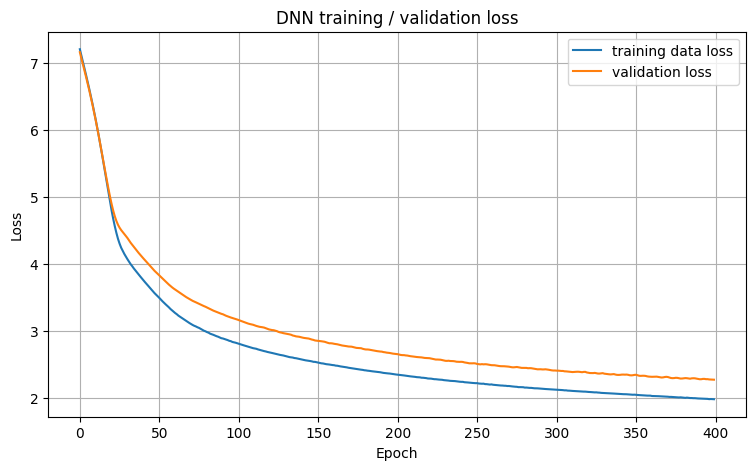

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

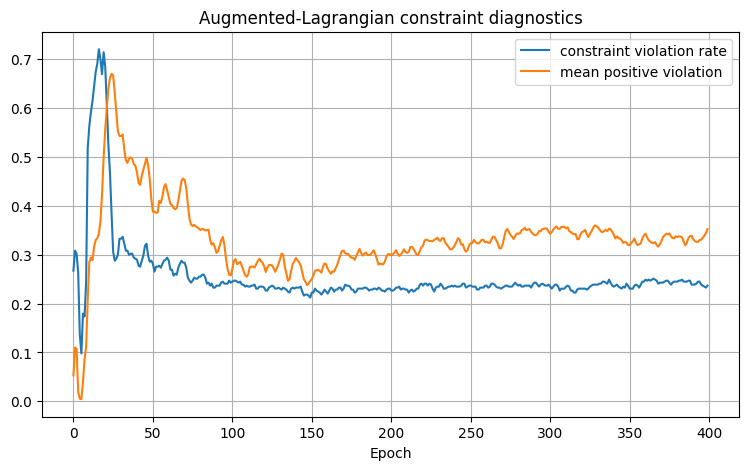

In [6]:
history_df=pd.read_csv(TRAINING_HISTORY_PATH)

plt.figure(figsize=(9,5))
plt.plot(history_df['train_data_loss'],label='training data loss')
plt.plot(history_df['val_loss'],label='validation loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.grid(True); plt.legend()
plt.title('DNN training / validation loss')
if USE_LAGRANGIAN_CONSTRAINTS:
  save_path = OUTPUT_DIR / 'dnn_training_validation_loss_with_lagrangian.png'
else:
  save_path = OUTPUT_DIR / 'dnn_training_validation_loss_without_lagrangian.png'
plt.savefig(save_path)
files.download(save_path)
plt.show()

if USE_LAGRANGIAN_CONSTRAINTS:
  plt.figure(figsize=(9,5))
  plt.plot(history_df['val_constraint_violation_rate'],label='constraint violation rate')
  plt.plot(history_df['val_constraint_mean_positive_violation'],label='mean positive violation')
  plt.xlabel('Epoch'); plt.grid(True); plt.legend()
  plt.title('Augmented-Lagrangian constraint diagnostics')
  save_path = save_path = OUTPUT_DIR / 'augmented_lagrangian_constraint_diagnostics.png'
  plt.savefig(save_path)
  files.download(save_path)
  plt.show()

## Test evaluation and floor/component diagnostics

In [ ]:
test_result = evaluate(test_loader, export_rows=True)

print('=' * 60)
print(f'{dnn} TEST RESULTS')
print('=' * 60)
print(f'Loss                 : {test_result["loss"]:.5f}')
print(f'Slot accuracy        : {test_result["slot_accuracy"]:.5f}')
print(f'Beam accuracy        : {test_result["beam_accuracy"]:.5f}')
print(f'Column accuracy      : {test_result["column_accuracy"]:.5f}')
print(f'Building exact match : {test_result["building_exact_match"]:.5f}')

print('\nAccuracy by floor:')
for floor, s in test_result['floor_stats'].items():
    print(
        f'{floor:>6s} | '
        f'beam={s["beam_accuracy"]:.5f} ({s["beam_total"]}) | '
        f'column={s["column_accuracy"]:.5f} ({s["column_total"]})'
    )

# Convert evaluation records to DataFrame
predictions = pd.DataFrame(test_result['records'])

# Save predictions as CSV
predictions.to_csv(
    PREDICTIONS_PATH,
    index=False,
    encoding='utf-8-sig'
)

print('\nSaved predictions:', PREDICTIONS_PATH)

# Display first 20 predictions
display(predictions.head(20))


# ============================================================
# Save test results to a text file
# ============================================================

text_path = OUTPUT_DIR / f'{dnn}_results.txt'

with open(text_path, "w", encoding="utf-8") as file:

    file.write(f'{dnn} TEST RESULTS\n')
    file.write('=' * 60 + '\n')

    file.write(f'Loss                 : {test_result["loss"]:.5f}\n')
    file.write(f'Slot accuracy        : {test_result["slot_accuracy"]:.5f}\n')
    file.write(f'Beam accuracy        : {test_result["beam_accuracy"]:.5f}\n')
    file.write(f'Column accuracy      : {test_result["column_accuracy"]:.5f}\n')
    file.write(f'Building exact match : {test_result["building_exact_match"]:.5f}\n')

    file.write('\nAccuracy by floor:\n')

    for floor, s in test_result['floor_stats'].items():
        file.write(
            f'{floor:>6s} | '
            f'beam={s["beam_accuracy"]:.5f} ({s["beam_total"]}) | '
            f'column={s["column_accuracy"]:.5f} ({s["column_total"]})\n'
        )

    # Save the first 20 prediction records
    file.write('\nFirst 20 predictions:\n')
    file.write(predictions.head(20).to_string(index=False))
    file.write('\n')

print('Saved test results:', text_path)

## Test-set constraint diagnostics

In [ ]:
test_pairs=make_cross_pairs(test_samples,allowed)
if USE_INTERFLOOR_COLUMN_MONOTONICITY:
    test_pairs += make_interfloor_column_pairs(test_samples)

test_cm=constraint_metrics(test_samples,test_pairs)
print('='*60)
print('TEST CONSTRAINT DIAGNOSTICS')
print('='*60)
for k,v in test_cm.items():
    print(f'{k}: {v}')
with open(text_path, "a", encoding="utf-8") as file:
  file.write('\nTEST CONSTRAINT DIAGNOSTICS\n')
  file.write('='*60 + '\n')
  for k,v in test_cm.items():
    file.write(f'{k}: {v}\n')

## Prediction for a new building (nominal sections)

`predict_building(...)` takes the same fundamental inputs as the network (floor count, load, individual spans, story heights) and returns the predicted **nominal** section of every beam / column slot, with the model confidence and top-k alternatives.
Slot names (`beam:RFL:GX1`, `column:1FL:C1`, ...) depend on the framing layout, so the valid slots are taken from the data files that have the same (floors, nx, ny).

In [ ]:
# slot sets per framing layout (floors, nx, ny), taken from the data files
STRUCTURE_SLOTS = defaultdict(set)
for _sm in train_samples + val_samples + test_samples:
    _f, _nx, _ny = (int(round(v)) for v in _sm.x[:3])
    STRUCTURE_SLOTS[(_f, _nx, _ny)].update(_sm.targets)

@torch.no_grad()
def predict_building(floors, load, x_spans, y_spans, story_heights, top_k=3):
    """Predict nominal sections for one building.

    floors        : int
    load          : vertical floor load [kN/m2]
    x_spans       : list of X span lengths [mm]
    y_spans       : list of Y span lengths [mm]
    story_heights : list of story heights [mm], one per floor
    """
    floors, nx, ny = int(floors), len(x_spans), len(y_spans)
    if len(story_heights) != floors:
        raise ValueError('len(story_heights) must equal floors')
    if not (MIN_FLOORS <= floors <= MAX_FLOORS and MIN_X_SPANS <= nx <= MAX_X_SPANS and MIN_Y_SPANS <= ny <= MAX_Y_SPANS):
        raise ValueError('floors / span counts outside the trained range')
    if min(list(x_spans) + list(y_spans)) < MIN_SPAN_MM or max(list(x_spans) + list(y_spans)) > MAX_SPAN_MM:
        raise ValueError('span length outside the trained range')
    if not (MIN_LOAD_KN_M2 <= load <= MAX_LOAD_KN_M2):
        print(f'WARNING: load {load} is outside the trained range [{MIN_LOAD_KN_M2}, {MAX_LOAD_KN_M2}]')
    valid = STRUCTURE_SLOTS.get((floors, nx, ny))
    if not valid:
        raise ValueError(f'No data file with floors={floors}, nx={nx}, ny={ny}; slot names for this layout are unknown')

    x = np.asarray(
        [floors, nx, ny, load,
         *x_spans, *([0.0] * (MAX_X_SPANS - nx)),
         *y_spans, *([0.0] * (MAX_Y_SPANS - ny)),
         *story_heights, *([0.0] * (MAX_FLOORS - floors))],
        dtype=np.float32
    )
    model.eval()
    lh, lb = model(torch.tensor(normalize_features(x), dtype=torch.float32, device=DEVICE).unsqueeze(0))

    rows = []
    for g, info in enumerate(SLOT_INFO):
        if info['slot'] not in valid:
            continue
        logits, cat = (lh[0, g], H_CATALOG) if info['kind'] == 'beam' else (lb[0, g], BOX_CATALOG)
        prob = logits.softmax(-1)
        top = prob.topk(min(top_k, len(cat)))
        best = cat[top.indices[0].item()]
        rows.append({
            'slot': info['slot'],
            'floor': info['floor_label'],
            'component_type': info['kind'],
            'predicted_nominal_section': best['name'],
            'nominal_dimensions_mm': 'x'.join(f'{v:g}' for v in best['values']),
            'confidence': round(top.values[0].item(), 4),
            'top_k': ', '.join(f"{cat[i]['name']} ({p:.2f})" for p, i in zip(top.values.tolist(), top.indices.tolist())),
        })
    return pd.DataFrame(rows)

# Example: the F1_X1_8000_Y1_4000_H3000_W8p0 building
example = predict_building(
    floors=1, load=8.0,
    x_spans=[8000], y_spans=[4000],
    story_heights=[3000],
)
display(example)

## Feature audit

In [ ]:
feature_audit=pd.DataFrame({
    'feature':FEATURE_NAMES,
    'source':(
        ['建物条件']*4
        + ['スパン割 / X']*MAX_X_SPANS
        + ['スパン割 / Y']*MAX_Y_SPANS
        + ['階高']*MAX_FLOORS
    )
})
display(feature_audit)

print(
    'The neural network input contains no section dimensions, section names, '
    'steel weights, member counts, member lengths, or target-slot labels.'
)

with open(text_path, "a", encoding="utf-8") as file:
  file.write('\nThe neural network input contains no section dimensions, section names, steel weights, member counts, member lengths, or target-slot labels.\n')
  file.write(feature_audit.to_string(index=False))
  file.write('\n')

In [ ]:
from google.colab import files
# Download the text file
files.download(text_path)

## Visualize predictions

In [7]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
from pathlib import Path
print(Path.cwd())

/content/drive/My Drive/research/dnn7


In [9]:
import os

# Check the current working directory
print("Before:", os.getcwd())

# Change to a new directory (absolute or relative path)
os.chdir("/content/drive/MyDrive/research/dnn7")

# Verify the change
print("After (Current Working Directory):", os.getcwd())


Before: /content/drive/My Drive/research/dnn7
After (Current Working Directory): /content/drive/MyDrive/research/dnn7


In [10]:
#assign again
from pathlib import Path
PROJECT_ROOT = Path.cwd()

DATASET_ROOT = Path(r'/content/drive/MyDrive/research/dataset-dnn7')
CATALOG_ROOT = DATASET_ROOT / 'dnn-catalog-1112'
H_CATALOG_FILE = 'JIS_SN_medium_narrow_H_list_DNN.csv'
BOX_CATALOG_FILE = 'BCR_square_tube_list_DNN.csv'
OUTPUT_DIR = PROJECT_ROOT / 'dnn-result'
print('PROJECT_ROOT:', PROJECT_ROOT)
print('DATASET_ROOT:', DATASET_ROOT)
print('CATALOG_ROOT:', CATALOG_ROOT)
print('H catalog file:', H_CATALOG_FILE, '/ box catalog file:', BOX_CATALOG_FILE)
print('OUTPUT_DIR:', OUTPUT_DIR)

PROJECT_ROOT: /content/drive/MyDrive/research/dnn7
DATASET_ROOT: /content/drive/MyDrive/research/dataset-dnn7
CATALOG_ROOT: /content/drive/MyDrive/research/dataset-dnn7/dnn-catalog-1112
H catalog file: JIS_SN_medium_narrow_H_list_DNN.csv / box catalog file: BCR_square_tube_list_DNN.csv
OUTPUT_DIR: /content/drive/MyDrive/research/dnn7/dnn-result


In [11]:
import re
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import os
from google.colab import files
#コード中で、
# import japanize_matplotlib

#上書きされたあとで、
# japanize_matplotlib.japanize()

In [12]:
# 2. Load the CSV file using its path in your Drive
# (Adjust the path below to match where your file is located)
file_path = "/content/drive/MyDrive/research/dnn7/dnn7_result/dnn7_test_predictions.csv"
df = pd.read_csv(file_path)

# Display the first few rows
df.head()

,file_name,slot,floor,component_type,predicted_catalog,true_catalog,predicted_dimension,true_dimension,is_correct
0,F1_X1_5000_Y1_4000_H3000_W6p5_model.csv,beam:RFL:GX1,RFL,beam,H-150x75x5x7x8,H-194x150x6x9x8,150.0,200.0,False
1,F1_X1_5000_Y1_4000_H3000_W6p5_model.csv,beam:RFL:GY1,RFL,beam,H-150x75x5x7x8,H-148x100x6x9x8,150.0,150.0,False
2,F1_X1_5000_Y1_4000_H3000_W6p5_model.csv,column:1FL:C1,1FL,column,B-150x150x6x15,B-150x150x6x15,150.0,150.0,True
3,F1_X1_9000_Y1_4000_H3000_W6p0_model.csv,beam:RFL:GX1,RFL,beam,H-390x300x10x16x13,H-294x200x8x12x13,400.0,300.0,False
4,F1_X1_9000_Y1_4000_H3000_W6p0_model.csv,beam:RFL:GY1,RFL,beam,H-150x75x5x7x8,H-200x100x5.5x8x8,150.0,200.0,False


In [13]:
print(df)

                                    file_name           slot floor  \
0     F1_X1_5000_Y1_4000_H3000_W6p5_model.csv   beam:RFL:GX1   RFL   
1     F1_X1_5000_Y1_4000_H3000_W6p5_model.csv   beam:RFL:GY1   RFL   
2     F1_X1_5000_Y1_4000_H3000_W6p5_model.csv  column:1FL:C1   1FL   
3     F1_X1_9000_Y1_4000_H3000_W6p0_model.csv   beam:RFL:GX1   RFL   
4     F1_X1_9000_Y1_4000_H3000_W6p0_model.csv   beam:RFL:GY1   RFL   
...                                       ...            ...   ...   
996   F5_X6_8000_Y1_4000_H3000_W6p0_model.csv  column:1FL:C1   1FL   
997   F5_X6_8000_Y1_4000_H3000_W6p0_model.csv  column:2FL:C1   2FL   
998   F5_X6_8000_Y1_4000_H3000_W6p0_model.csv  column:3FL:C1   3FL   
999   F5_X6_8000_Y1_4000_H3000_W6p0_model.csv  column:4FL:C1   4FL   
1000  F5_X6_8000_Y1_4000_H3000_W6p0_model.csv  column:5FL:C1   5FL   

     component_type   predicted_catalog       true_catalog  \
0              beam      H-150x75x5x7x8    H-194x150x6x9x8   
1              beam      H-150x75x5

In [14]:
import pandas as pd
import numpy as np
import re

# ============================================================
# Nominal dimensions are taken from the CATALOG files.
#   H-shape : nominal_H_mm, nominal_B_mm   (e.g. H-244x175x7x11x13 -> 250, 175)
#   BCR box : D_mm, t_mm                   (e.g. B-200x200x8x20    -> 200, 8)
# A name in `df` may be either
#   * an exact section name  (H-244x175x7x11x13 / B-200x200x8x20), or
#   * a nominal class name   (H-250x175 / B-200x8)
# Both are resolved to the same nominal values, so older and newer
# prediction files work with the same code.
# ============================================================

def _read_catalog_csv(path):
    return pd.read_csv(path, encoding='utf-8-sig')

h_cat = _read_catalog_csv(CATALOG_ROOT / H_CATALOG_FILE)    # all rows, incl. enabled == 0
box_cat = _read_catalog_csv(CATALOG_ROOT / BOX_CATALOG_FILE)

def build_lookup(cat, key_cols, prefix):
    lookup = {}
    for _, r in cat.iterrows():
        vals = tuple(float(r[c]) for c in key_cols)
        lookup[str(r['name']).strip()] = vals                              # exact name
        lookup[f'{prefix}-' + 'x'.join(f'{v:g}' for v in vals)] = vals     # nominal class name
    return lookup

H_LOOKUP = build_lookup(h_cat, ('nominal_H_mm', 'nominal_B_mm'), 'H')
BOX_LOOKUP = build_lookup(box_cat, ('D_mm', 't_mm'), 'B')

def normalize_name(name):
    if pd.isna(name):
        return None
    name = str(name).strip()
    return re.sub(r'^[□■]\s*-?\s*', 'B-', name)       # □-200x200x8x20 -> B-200x200x8x20

def get_section_type(name):
    name = normalize_name(name)
    if name is None:
        return np.nan
    if name.startswith('H-'):
        return 'h'
    if name.startswith('B-'):
        return 'box'
    return np.nan

def nominal_dims(name, section_type):
    """name -> (nominal H, nominal B) for 'h',  (D, t) for 'box',  (nan, nan) otherwise."""
    name = normalize_name(name)
    if name is not None:
        lookup = H_LOOKUP if section_type == 'h' else BOX_LOOKUP if section_type == 'box' else {}
        if name in lookup:
            return lookup[name]
    return (np.nan, np.nan)

df_transformed = df.copy()
df_transformed['section_type'] = df_transformed['true_catalog'].apply(get_section_type)

def add_dims(prefix, name_col):
    """Add {prefix}_H/_B (beams) and {prefix}_D/_t (columns) from the catalog."""
    dims = [nominal_dims(n, get_section_type(n)) for n in df_transformed[name_col]]
    is_h = df_transformed[name_col].apply(get_section_type).eq('h').to_numpy()
    arr = np.array(dims, dtype=float)
    df_transformed[f'{prefix}_H'] = np.where(is_h, arr[:, 0], np.nan)
    df_transformed[f'{prefix}_B'] = np.where(is_h, arr[:, 1], np.nan)
    df_transformed[f'{prefix}_D'] = np.where(~is_h, arr[:, 0], np.nan)
    df_transformed[f'{prefix}_t'] = np.where(~is_h, arr[:, 1], np.nan)

add_dims('pred', 'predicted_catalog')
add_dims('true', 'true_catalog')

# names that could not be found in the catalog
for col in ('predicted_catalog', 'true_catalog'):
    p = 'pred' if col == 'predicted_catalog' else 'true'
    unresolved = df_transformed[
        df_transformed[col].notna()
        & df_transformed[[f'{p}_H', f'{p}_D']].isna().all(axis=1)
    ][col].unique()
    if len(unresolved):
        print(f'WARNING: {col} names not found in catalog:', list(unresolved)[:10])

# is_correct judged on the nominal class (exact names that share a nominal size count as equal)
df_transformed['is_correct_nominal'] = (
    df_transformed[['pred_H', 'pred_B', 'pred_D', 'pred_t']].fillna(-1)
    .eq(df_transformed[['true_H', 'true_B', 'true_D', 'true_t']].fillna(-1).to_numpy()).all(axis=1)
)

df_transformed = df_transformed[
    [
        'file_name', 'slot', 'section_type',
        'predicted_catalog', 'true_catalog', 'is_correct', 'is_correct_nominal',
        'pred_H', 'pred_B', 'pred_D', 'pred_t',
        'true_H', 'true_B', 'true_D', 'true_t',
    ]
]

print(df_transformed.head())
print(df_transformed.shape)

                                 file_name           slot section_type  \
0  F1_X1_5000_Y1_4000_H3000_W6p5_model.csv   beam:RFL:GX1            h   
1  F1_X1_5000_Y1_4000_H3000_W6p5_model.csv   beam:RFL:GY1            h   
2  F1_X1_5000_Y1_4000_H3000_W6p5_model.csv  column:1FL:C1          box   
3  F1_X1_9000_Y1_4000_H3000_W6p0_model.csv   beam:RFL:GX1            h   
4  F1_X1_9000_Y1_4000_H3000_W6p0_model.csv   beam:RFL:GY1            h   

    predicted_catalog       true_catalog  is_correct  is_correct_nominal  \
0      H-150x75x5x7x8    H-194x150x6x9x8       False               False   
1      H-150x75x5x7x8    H-148x100x6x9x8       False               False   
2      B-150x150x6x15     B-150x150x6x15        True                True   
3  H-390x300x10x16x13  H-294x200x8x12x13       False               False   
4      H-150x75x5x7x8  H-200x100x5.5x8x8       False               False   

   pred_H  pred_B  pred_D  pred_t  true_H  true_B  true_D  true_t  
0   150.0    75.0     NaN     

In [15]:
df = df_transformed.copy()
print(df)

                                    file_name           slot section_type  \
0     F1_X1_5000_Y1_4000_H3000_W6p5_model.csv   beam:RFL:GX1            h   
1     F1_X1_5000_Y1_4000_H3000_W6p5_model.csv   beam:RFL:GY1            h   
2     F1_X1_5000_Y1_4000_H3000_W6p5_model.csv  column:1FL:C1          box   
3     F1_X1_9000_Y1_4000_H3000_W6p0_model.csv   beam:RFL:GX1            h   
4     F1_X1_9000_Y1_4000_H3000_W6p0_model.csv   beam:RFL:GY1            h   
...                                       ...            ...          ...   
996   F5_X6_8000_Y1_4000_H3000_W6p0_model.csv  column:1FL:C1          box   
997   F5_X6_8000_Y1_4000_H3000_W6p0_model.csv  column:2FL:C1          box   
998   F5_X6_8000_Y1_4000_H3000_W6p0_model.csv  column:3FL:C1          box   
999   F5_X6_8000_Y1_4000_H3000_W6p0_model.csv  column:4FL:C1          box   
1000  F5_X6_8000_Y1_4000_H3000_W6p0_model.csv  column:5FL:C1          box   

       predicted_catalog       true_catalog  is_correct  is_correct_nominal

In [16]:
df.columns

Index(['file_name', 'slot', 'section_type', 'predicted_catalog',
       'true_catalog', 'is_correct', 'is_correct_nominal', 'pred_H', 'pred_B',
       'pred_D', 'pred_t', 'true_H', 'true_B', 'true_D', 'true_t'],
      dtype='object')

In [17]:
import os
os.makedirs('dnn-result', exist_ok=True)


In [18]:
print(df)

                                    file_name           slot section_type  \
0     F1_X1_5000_Y1_4000_H3000_W6p5_model.csv   beam:RFL:GX1            h   
1     F1_X1_5000_Y1_4000_H3000_W6p5_model.csv   beam:RFL:GY1            h   
2     F1_X1_5000_Y1_4000_H3000_W6p5_model.csv  column:1FL:C1          box   
3     F1_X1_9000_Y1_4000_H3000_W6p0_model.csv   beam:RFL:GX1            h   
4     F1_X1_9000_Y1_4000_H3000_W6p0_model.csv   beam:RFL:GY1            h   
...                                       ...            ...          ...   
996   F5_X6_8000_Y1_4000_H3000_W6p0_model.csv  column:1FL:C1          box   
997   F5_X6_8000_Y1_4000_H3000_W6p0_model.csv  column:2FL:C1          box   
998   F5_X6_8000_Y1_4000_H3000_W6p0_model.csv  column:3FL:C1          box   
999   F5_X6_8000_Y1_4000_H3000_W6p0_model.csv  column:4FL:C1          box   
1000  F5_X6_8000_Y1_4000_H3000_W6p0_model.csv  column:5FL:C1          box   

       predicted_catalog       true_catalog  is_correct  is_correct_nominal

In [19]:
import pandas as pd
from google.colab import files

# Save to the temporary Colab workspace (index=False avoids adding a row number column)
#df.to_csv('output.csv', index=False)

# Download to your local machine
save_path = OUTPUT_DIR / f'df_transformed_{dnn}.csv'
df.to_csv(save_path, index=False)
#files.download(save_path)


## Read the CSV file

In [20]:
# 2. Load the CSV file using its path in your Drive
# (Adjust the path below to match where your file is located)
file_path = f"/content/drive/MyDrive/research/dnn7/dnn-result/df_transformed_{dnn}.csv"
df = pd.read_csv(file_path)

# Display the first few rows
df.head()

,file_name,slot,section_type,predicted_catalog,true_catalog,is_correct,is_correct_nominal,pred_H,pred_B,pred_D,pred_t,true_H,true_B,true_D,true_t
0,F1_X1_5000_Y1_4000_H3000_W6p5_model.csv,beam:RFL:GX1,h,H-150x75x5x7x8,H-194x150x6x9x8,False,False,150.0,75.0,NaN,NaN,200.0,150.0,NaN,NaN
1,F1_X1_5000_Y1_4000_H3000_W6p5_model.csv,beam:RFL:GY1,h,H-150x75x5x7x8,H-148x100x6x9x8,False,False,150.0,75.0,NaN,NaN,150.0,100.0,NaN,NaN
2,F1_X1_5000_Y1_4000_H3000_W6p5_model.csv,column:1FL:C1,box,B-150x150x6x15,B-150x150x6x15,True,True,NaN,NaN,150.0,6.0,NaN,NaN,150.0,6.0
3,F1_X1_9000_Y1_4000_H3000_W6p0_model.csv,beam:RFL:GX1,h,H-390x300x10x16x13,H-294x200x8x12x13,False,False,400.0,300.0,NaN,NaN,300.0,200.0,NaN,NaN
4,F1_X1_9000_Y1_4000_H3000_W6p0_model.csv,beam:RFL:GY1,h,H-150x75x5x7x8,H-200x100x5.5x8x8,False,False,150.0,75.0,NaN,NaN,200.0,100.0,NaN,NaN


### Member H-Length vs. X-Span Length

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved graph to: /content/drive/MyDrive/research/dnn7/dnn-result/DNN7_nominalMember_H_Length_vs_X_Span_Length_with_Constraints.png

Selected building condition:
Building condition key: F1_XSPAN_Y1_4000_H3000_W8p0_model.csv | beam:RFL:GX1
Number of X-span lengths available for this condition: 5
X-span lengths plotted: [4000, 5000, 6000, 8000, 9000]

Components plotted:
[1] X-Span Length: 4000 mm
    Component: F1_X4_4000_Y1_4000_H3000_W8p0_model.csv | beam:RFL:GX1
    Predicted H:    150.0 mm
    Ground Truth H: 200.0 mm
------------------------------------------------------------------------------------------------------------------------
[2] X-Span Length: 5000 mm
    Component: F1_X4_5000_Y1_4000_H3000_W8p0_model.csv | beam:RFL:GX1
    Predicted H:    150.0 mm
    Ground Truth H: 250.0 mm
------------------------------------------------------------------------------------------------------------------------
[3] X-Span Length: 6000 mm
    Component: F1_X2_6000_Y1_4000_H3000_W8p0_model.

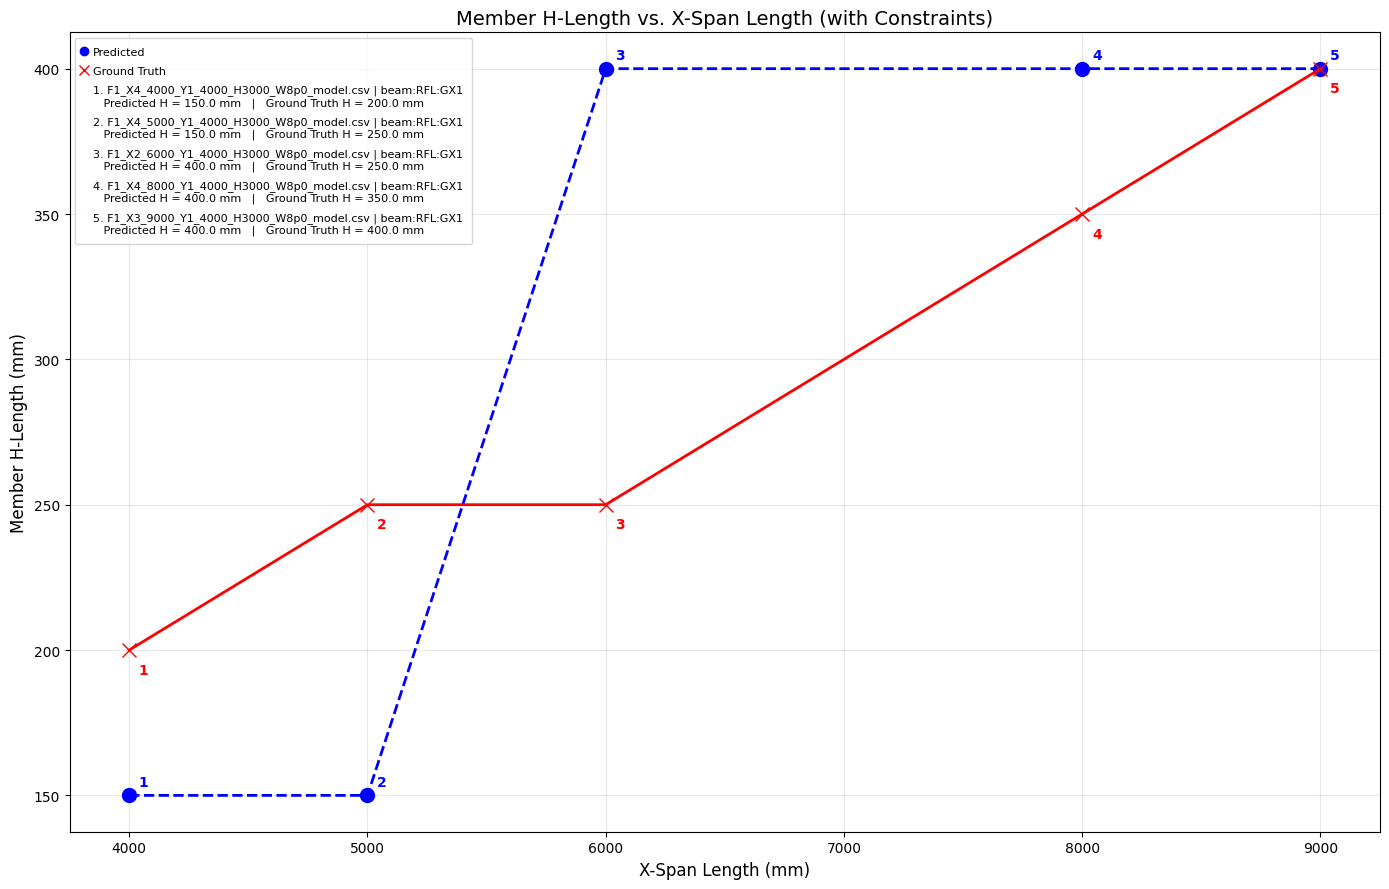

In [22]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


# ============================================================
# 1. Load CSV
# ============================================================

# Adjust the path below to match where your file is located.
# file_path = '/content/drive/My Drive/research/DNN6/dnn_result/test_catalog_predictions_lagrangian.csv'
# df = pd.read_csv(file_path)


# ============================================================
# 2. Extract X-span length from file_name
# ============================================================

def extract_x_span_length(file_name):
    """
    Extract the X-span length from the file name.

    Example:
        F1_X1_5000_Y1_4000_H3000_W8p0_model.csv

    X1_5000 means:
        X-span count   = 1
        X-span length  = 5000 mm
    """

    match = re.search(
        r'_X\d+_(\d+)_',
        file_name
    )

    if match is None:
        return pd.NA

    return int(match.group(1))


df['x_span_length'] = df['file_name'].apply(
    extract_x_span_length
)


# ============================================================
# 3. Create a building-condition key
# ============================================================

def create_building_condition_key(file_name, slot):
    """
    Create a key representing the building conditions while
    excluding the X-span information.

    Example:

        F1_X1_5000_Y1_4000_H3000_W8p0_model.csv

    becomes approximately:

        F1_XSPAN_Y1_4000_H3000_W8p0_model.csv

    Therefore, X-span length is allowed to vary, while the
    other filename conditions remain fixed.

    The slot is also included so that the same member is
    compared across different X-span lengths.
    """

    if pd.isna(file_name) or pd.isna(slot):
        return pd.NA

    normalized_file_name = re.sub(
        r'_X\d+_\d+_',
        '_XSPAN_',
        file_name
    )

    return f'{normalized_file_name} | {slot}'


df['building_condition_key'] = df.apply(
    lambda row: create_building_condition_key(
        row['file_name'],
        row['slot']
    ),
    axis=1
)


# ============================================================
# 4. Select H-section beams
# ============================================================

df_h = df[
    (df['section_type'] == 'h') &
    (df['slot'].str.startswith('beam:', na=False))
].copy()


# Remove rows for which the required values are unavailable
df_h = df_h.dropna(
    subset=[
        'x_span_length',
        'pred_H',
        'true_H',
        'file_name',
        'slot',
        'building_condition_key'
    ]
)


# ============================================================
# 5. Find the most consistent building condition
# ============================================================

# Count how many different X-span lengths are available
# for each building condition.

condition_coverage = (
    df_h
    .groupby('building_condition_key')['x_span_length']
    .nunique()
    .reset_index(name='number_of_x_span_lengths')
)


# Find the maximum possible coverage
max_coverage = condition_coverage[
    'number_of_x_span_lengths'
].max()


# Keep only building conditions having the maximum coverage
best_conditions = condition_coverage[
    condition_coverage['number_of_x_span_lengths']
    == max_coverage
].copy()


# ------------------------------------------------------------
# If several conditions have the same coverage, use a
# deterministic alphabetical tie-breaker.
# ------------------------------------------------------------

best_conditions = best_conditions.sort_values(
    'building_condition_key'
)

selected_condition = best_conditions.iloc[0][
    'building_condition_key'
]


# ============================================================
# 6. Keep ONLY the selected building condition
# ============================================================

df_selected = df_h[
    df_h['building_condition_key']
    == selected_condition
].copy()


# ============================================================
# 7. Select ONE data point for each X-span length
# ============================================================

# There should now be the SAME building condition for every
# selected X-span length.
#
# If duplicate rows still exist for a given X-span length,
# sort deterministically and keep the first one.

df_selected = df_selected.sort_values(
    [
        'x_span_length',
        'file_name',
        'slot'
    ]
)


summary = (
    df_selected
    .drop_duplicates(
        subset='x_span_length',
        keep='first'
    )
    .sort_values('x_span_length')
    .reset_index(drop=True)
)


# ============================================================
# 8. Check that data exist
# ============================================================

if summary.empty:
    raise ValueError(
        'No valid H-section beam data were found in the CSV file.'
    )


# ============================================================
# 9. Generate graph
# ============================================================

fig, ax = plt.subplots(
    figsize=(14, 9)
)


# ============================================================
# 10. Plot predicted values
# ============================================================

ax.plot(
    summary['x_span_length'],
    summary['pred_H'],
    marker='o',
    linestyle='--',
    color='blue',
    linewidth=2,
    markersize=10,
    label='Predicted'
)


# ============================================================
# 11. Plot ground-truth values
# ============================================================

ax.plot(
    summary['x_span_length'],
    summary['true_H'],
    marker='x',
    linestyle='-',
    color='red',
    linewidth=2,
    markersize=10,
    label='Ground Truth'
)


# ============================================================
# 12. Add numbers to the plotted points
# ============================================================

for i, (_, row) in enumerate(
    summary.iterrows(),
    start=1
):

    # Number next to predicted point
    ax.annotate(
        str(i),
        xy=(
            row['x_span_length'],
            row['pred_H']
        ),
        xytext=(7, 7),
        textcoords='offset points',
        color='blue',
        fontsize=10,
        fontweight='bold'
    )

    # Number next to ground-truth point
    ax.annotate(
        str(i),
        xy=(
            row['x_span_length'],
            row['true_H']
        ),
        xytext=(7, -17),
        textcoords='offset points',
        color='red',
        fontsize=10,
        fontweight='bold'
    )


# ============================================================
# 13. Create CUSTOM legend
# ============================================================

legend_handles = [
    Line2D(
        [0],
        [0],
        color='blue',
        linestyle='--',
        marker='o',
        linewidth=1.5,
        markersize=6,
        label='Predicted'
    ),

    Line2D(
        [0],
        [0],
        color='red',
        linestyle='-',
        marker='x',
        linewidth=1.5,
        markersize=7,
        label='Ground Truth'
    )
]


# ------------------------------------------------------------
# Add one legend entry for each plotted component
# ------------------------------------------------------------

for i, (_, row) in enumerate(
    summary.iterrows(),
    start=1
):

    component_name = (
        f'{row["file_name"]} | {row["slot"]}'
    )

    legend_text = (
        f'{i}. {component_name}\n'
        f'   Predicted H = {row["pred_H"]} mm'
        f'   |   Ground Truth H = {row["true_H"]} mm'
    )

    legend_handles.append(
        Line2D(
            [0],
            [0],
            color='none',
            linestyle='None',
            marker=None,
            label=legend_text
        )
    )


# ------------------------------------------------------------
# Display custom legend
# ------------------------------------------------------------

ax.legend(
    handles=legend_handles,
    loc='best',
    fontsize=8,
    frameon=True,
    handlelength=0,
    borderpad=0.8,
    labelspacing=0.8
)


# ============================================================
# 14. Axis labels
# ============================================================

ax.set_xlabel(
    'X-Span Length (mm)',
    fontsize=12
)

ax.set_ylabel(
    'Member H-Length (mm)',
    fontsize=12
)


# ============================================================
# 15. Title
# ============================================================

if USE_LAGRANGIAN_CONSTRAINTS:
  ax.set_title(
    'Member H-Length vs. X-Span Length (with Constraints)',
    fontsize=14
)
else:
  ax.set_title(
    'Member H-Length vs. X-Span Length (without Constraints)',
    fontsize=14
)




# ============================================================
# 16. Grid
# ============================================================

ax.grid(
    True,
    alpha=0.3
)


# ============================================================
# 17. Adjust layout
# ============================================================

plt.tight_layout()


# ============================================================
# 18. Save graph
# ============================================================

save_dir = OUTPUT_DIR

os.makedirs(
    save_dir,
    exist_ok=True
)
if USE_LAGRANGIAN_CONSTRAINTS:
  output_path = os.path.join(
    save_dir,
    f'{dnn}_Member_H_Length_vs_X_Span_Length_with_Constraints.png'
  )
else:
  output_path = os.path.join(
    save_dir,
    f'{dnn}_Member_H_Length_vs_X_Span_Length_without_Constraints.png'
  )

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches='tight'
)

files.download(output_path)


# ============================================================
# 19. Output selected building condition
# ============================================================

print(
    f'Saved graph to: {output_path}'
)

print('\nSelected building condition:')
print('=' * 120)

print(
    f'Building condition key: {selected_condition}'
)

print(
    f'Number of X-span lengths available for this condition: '
    f'{max_coverage}'
)

print(
    f'X-span lengths plotted: '
    f'{summary["x_span_length"].tolist()}'
)


# ============================================================
# 20. Output selected components
# ============================================================

print('\nComponents plotted:')
print('=' * 120)

for i, (_, row) in enumerate(
    summary.iterrows(),
    start=1
):

    component_name = (
        f'{row["file_name"]} | {row["slot"]}'
    )

    print(
        f'[{i}] X-Span Length: '
        f'{row["x_span_length"]} mm'
    )

    print(
        f'    Component: {component_name}'
    )

    print(
        f'    Predicted H:    {row["pred_H"]} mm'
    )

    print(
        f'    Ground Truth H: {row["true_H"]} mm'
    )

    print('-' * 120)


print(
    f'Total number of unique X-span lengths plotted: '
    f'{summary["x_span_length"].nunique()}'
)


# ============================================================
# 21. Display graph
# ============================================================

plt.show()

### Member_H_Length_vs_Building_Load

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved graph to: /content/drive/MyDrive/research/dnn7/dnn-result/DNN7_nominal_Member_H_Length_vs_Building_Load_with_Constraints.png

Selected building condition:
Building condition key: F5_X4_7000_Y1_4000_H3000_WLOAD_model.csv | beam:2FL:GX1
Number of load values available for this condition: 3
Load values plotted: [6.0, 6.5, 7.5]

Components plotted:
[1] Load: 6 kN/m²
    Component: F5_X4_7000_Y1_4000_H3000_W6p0_model.csv | beam:2FL:GX1
    Predicted H:    400.0 mm
    Ground Truth H: 400.0 mm
------------------------------------------------------------------------------------------------------------------------
[2] Load: 6.5 kN/m²
    Component: F5_X4_7000_Y1_4000_H3000_W6p5_model.csv | beam:2FL:GX1
    Predicted H:    400.0 mm
    Ground Truth H: 400.0 mm
------------------------------------------------------------------------------------------------------------------------
[3] Load: 7.5 kN/m²
    Component: F5_X4_7000_Y1_4000_H3000_W7p5_model.csv | beam:2FL:GX1
    Predicted H:    4

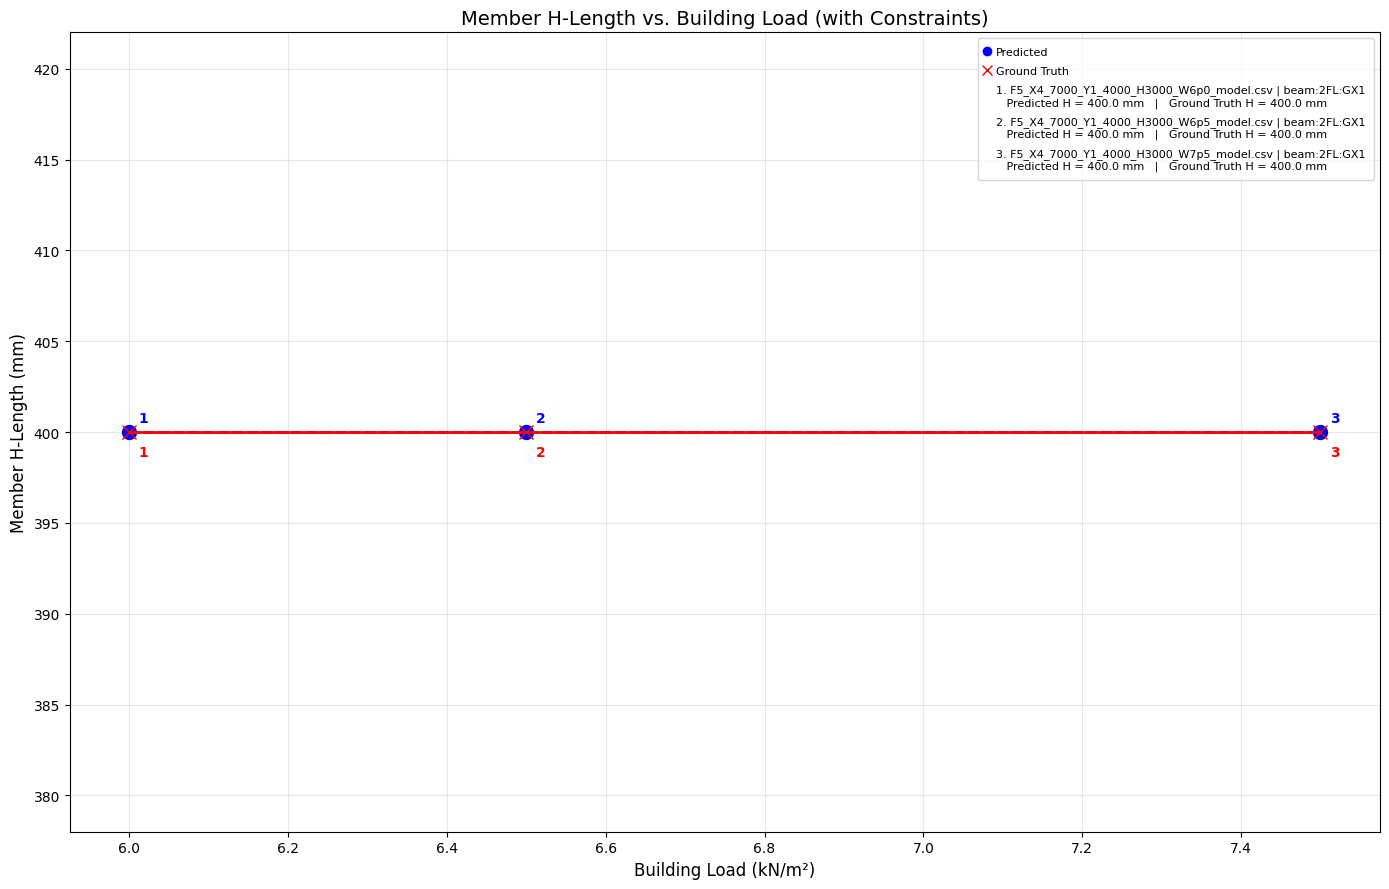

In [23]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


# ============================================================
# 1. Load CSV
# ============================================================

# Adjust the path below to match where your file is located.
# file_path = '/content/drive/My Drive/research/DNN6/dnn_result/test_catalog_predictions_lagrangian.csv'
# df = pd.read_csv(file_path)


# ============================================================
# 2. Extract building load from file_name
# ============================================================

def extract_load(file_name):
    """
    Extract the building load from the file name.

    Example:
        F1_X1_5000_Y1_4000_H3000_W8p0_model.csv

    W8p0 -> load = 8.0
    """

    match = re.search(
        r'_W([\d.]+p?[\d]*)_',
        file_name
    )

    if match is None:
        return pd.NA

    load_str = match.group(1).replace('p', '.')

    return float(load_str)


df['load'] = df['file_name'].apply(
    extract_load
)


# ============================================================
# 3. Create a building-condition key
# ============================================================

def create_building_condition_key(file_name, slot):
    """
    Create a building-condition key while excluding
    the building load W.

    Example:

        F1_X1_5000_Y1_4000_H3000_W8p0_model.csv

    becomes approximately:

        F1_X1_5000_Y1_4000_H3000_WLOAD_model.csv

    Therefore, the following conditions are kept constant:

        - Floor
        - X-span count
        - X-span length
        - Y-span count
        - Y-span length
        - Story height
        - Beam slot

    while the building load W is allowed to vary.
    """

    if pd.isna(file_name) or pd.isna(slot):
        return pd.NA

    # Replace only the W-value.
    #
    # W8p0  -> WLOAD
    # W7p0  -> WLOAD
    # W6p5  -> WLOAD
    #
    # Everything else in the filename remains unchanged.
    normalized_file_name = re.sub(
        r'_W[\d.]+p?[\d]*_',
        '_WLOAD_',
        file_name
    )

    return f'{normalized_file_name} | {slot}'


df['building_condition_key'] = df.apply(
    lambda row: create_building_condition_key(
        row['file_name'],
        row['slot']
    ),
    axis=1
)


# ============================================================
# 4. Select H-section structural members
# ============================================================

df_h = df[
    (df['section_type'] == 'h') &
    (df['slot'].str.startswith('beam:', na=False))
].copy()


# Remove rows with missing required values
df_h = df_h.dropna(
    subset=[
        'load',
        'pred_H',
        'true_H',
        'file_name',
        'slot',
        'building_condition_key'
    ]
)


# ============================================================
# 5. Find the most consistent building condition
# ============================================================

# Count how many DISTINCT load values are available
# for each building condition.

condition_coverage = (
    df_h
    .groupby('building_condition_key')['load']
    .nunique()
    .reset_index(name='number_of_load_values')
)


# Find the maximum number of load values represented
# by any single building condition.

max_coverage = condition_coverage[
    'number_of_load_values'
].max()


# Keep only conditions having the maximum coverage.

best_conditions = condition_coverage[
    condition_coverage['number_of_load_values']
    == max_coverage
].copy()


# ------------------------------------------------------------
# If multiple conditions have the same coverage, use a
# deterministic alphabetical tie-breaker.
# ------------------------------------------------------------

best_conditions = best_conditions.sort_values(
    'building_condition_key'
)


selected_condition = best_conditions.iloc[0][
    'building_condition_key'
]


# ============================================================
# 6. Keep ONLY the selected building condition
# ============================================================

df_selected = df_h[
    df_h['building_condition_key']
    == selected_condition
].copy()


# ============================================================
# 7. Select ONE data point for each load value
# ============================================================

# Sort first so that the selection is deterministic.

df_selected = df_selected.sort_values(
    [
        'load',
        'file_name',
        'slot'
    ]
)


# Keep one component for each load value.

summary = (
    df_selected
    .drop_duplicates(
        subset='load',
        keep='first'
    )
    .sort_values('load')
    .reset_index(drop=True)
)


# ============================================================
# 8. Check that data exist
# ============================================================

if summary.empty:
    raise ValueError(
        'No valid H-section beam data were found in the CSV file.'
    )


# ============================================================
# 9. Generate graph
# ============================================================

fig, ax = plt.subplots(
    figsize=(14, 9)
)


# ============================================================
# 10. Plot predicted values
# ============================================================

ax.plot(
    summary['load'],
    summary['pred_H'],
    marker='o',
    linestyle='--',
    color='blue',
    linewidth=2,
    markersize=10,
    label='Predicted'
)


# ============================================================
# 11. Plot ground-truth values
# ============================================================

ax.plot(
    summary['load'],
    summary['true_H'],
    marker='x',
    linestyle='-',
    color='red',
    linewidth=2,
    markersize=10,
    label='Ground Truth'
)


# ============================================================
# 12. Add numbers to the plotted points
# ============================================================

for i, (_, row) in enumerate(
    summary.iterrows(),
    start=1
):

    # Number next to predicted point
    ax.annotate(
        str(i),
        xy=(
            row['load'],
            row['pred_H']
        ),
        xytext=(7, 7),
        textcoords='offset points',
        color='blue',
        fontsize=10,
        fontweight='bold'
    )

    # Number next to ground-truth point
    ax.annotate(
        str(i),
        xy=(
            row['load'],
            row['true_H']
        ),
        xytext=(7, -17),
        textcoords='offset points',
        color='red',
        fontsize=10,
        fontweight='bold'
    )


# ============================================================
# 13. Create a CUSTOM legend
# ============================================================

# ------------------------------------------------------------
# First: legend entries explaining the two line types
# ------------------------------------------------------------

legend_handles = [
    Line2D(
        [0],
        [0],
        color='blue',
        linestyle='--',
        marker='o',
        linewidth=1.5,
        markersize=6,
        label='Predicted'
    ),

    Line2D(
        [0],
        [0],
        color='red',
        linestyle='-',
        marker='x',
        linewidth=1.5,
        markersize=7,
        label='Ground Truth'
    )
]


# ------------------------------------------------------------
# Second: one legend entry for each numbered component
# ------------------------------------------------------------

for i, (_, row) in enumerate(
    summary.iterrows(),
    start=1
):

    component_name = (
        f'{row["file_name"]} | {row["slot"]}'
    )

    legend_text = (
        f'{i}. {component_name}\n'
        f'   Predicted H = {row["pred_H"]} mm'
        f'   |   Ground Truth H = {row["true_H"]} mm'
    )

    # Invisible legend handle.
    #
    # The component number is included directly in
    # legend_text, so no additional numbered marker is used.
    legend_handles.append(
        Line2D(
            [0],
            [0],
            color='none',
            linestyle='None',
            marker=None,
            label=legend_text
        )
    )


# ------------------------------------------------------------
# Display the custom legend
# ------------------------------------------------------------

ax.legend(
    handles=legend_handles,
    loc='best',
    fontsize=8,
    frameon=True,
    handlelength=0,
    borderpad=0.8,
    labelspacing=0.8
)


# ============================================================
# 14. Axis labels
# ============================================================

ax.set_xlabel(
    'Building Load (kN/m²)',
    fontsize=12
)

ax.set_ylabel(
    'Member H-Length (mm)',
    fontsize=12
)


# ============================================================
# 15. Title
# ============================================================

if USE_LAGRANGIAN_CONSTRAINTS:
  ax.set_title(
    'Member H-Length vs. Building Load (with Constraints)',
    fontsize=14
)
else:
  ax.set_title(
  'Member H-Length vs. Building Load (without Constraints)',
  fontsize=14
)




# ============================================================
# 16. Grid
# ============================================================

ax.grid(
    True,
    alpha=0.3
)


# ============================================================
# 17. Adjust layout
# ============================================================

plt.tight_layout()


# ============================================================
# 18. Save graph
# ============================================================

save_dir = OUTPUT_DIR

os.makedirs(
    save_dir,
    exist_ok=True
)

if USE_LAGRANGIAN_CONSTRAINTS:
  output_path = os.path.join(
      save_dir,
      f'{dnn}_Member_H_Length_vs_Building_Load_with_Constraints.png'
  )
else:
  output_path = os.path.join(
      save_dir,
      f'{dnn}_Member_H_Length_vs_Building_Load_without_Constraints.png'
  )

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches='tight'
)

files.download(output_path)


# ============================================================
# 19. Output selected building condition
# ============================================================

print(
    f'Saved graph to: {output_path}'
)

print('\nSelected building condition:')
print('=' * 120)

print(
    f'Building condition key: {selected_condition}'
)

print(
    f'Number of load values available for this condition: '
    f'{max_coverage}'
)

print(
    f'Load values plotted: '
    f'{summary["load"].tolist()}'
)


# ============================================================
# 20. Output plotted components
# ============================================================

print('\nComponents plotted:')
print('=' * 120)

for i, (_, row) in enumerate(
    summary.iterrows(),
    start=1
):

    component_name = (
        f'{row["file_name"]} | {row["slot"]}'
    )

    print(
        f'[{i}] Load: {row["load"]:g} kN/m²'
    )

    print(
        f'    Component: {component_name}'
    )

    print(
        f'    Predicted H:    {row["pred_H"]} mm'
    )

    print(
        f'    Ground Truth H: {row["true_H"]} mm'
    )

    print('-' * 120)


print(
    f'Total number of unique load values plotted: '
    f'{summary["load"].nunique()}'
)


# ============================================================
# 21. Display graph
# ============================================================

plt.show()

### Square Steel Section D-Dimension vs. Building Load

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved graph to: /content/drive/MyDrive/research/dnn7/dnn-result/DNN7_nominal_Square_Steel_D_Dimension_vs_Building_Load_Lagrangian.png

Selected building condition:
Building condition key: F5_X4_7000_Y1_4000_H3000_WLOAD_model.csv | column:1FL:C1
Number of load values available for this condition: 3
Load values plotted: [6.0, 6.5, 7.5]

Square steel components plotted:
[1] Load: 6 kN/m²
    Component: F5_X4_7000_Y1_4000_H3000_W6p0_model.csv | column:1FL:C1
    Predicted D:    300.0 mm
    Ground Truth D: 300.0 mm
------------------------------------------------------------------------------------------------------------------------
[2] Load: 6.5 kN/m²
    Component: F5_X4_7000_Y1_4000_H3000_W6p5_model.csv | column:1FL:C1
    Predicted D:    350.0 mm
    Ground Truth D: 350.0 mm
------------------------------------------------------------------------------------------------------------------------
[3] Load: 7.5 kN/m²
    Component: F5_X4_7000_Y1_4000_H3000_W7p5_model.csv | column:1FL:C1
 

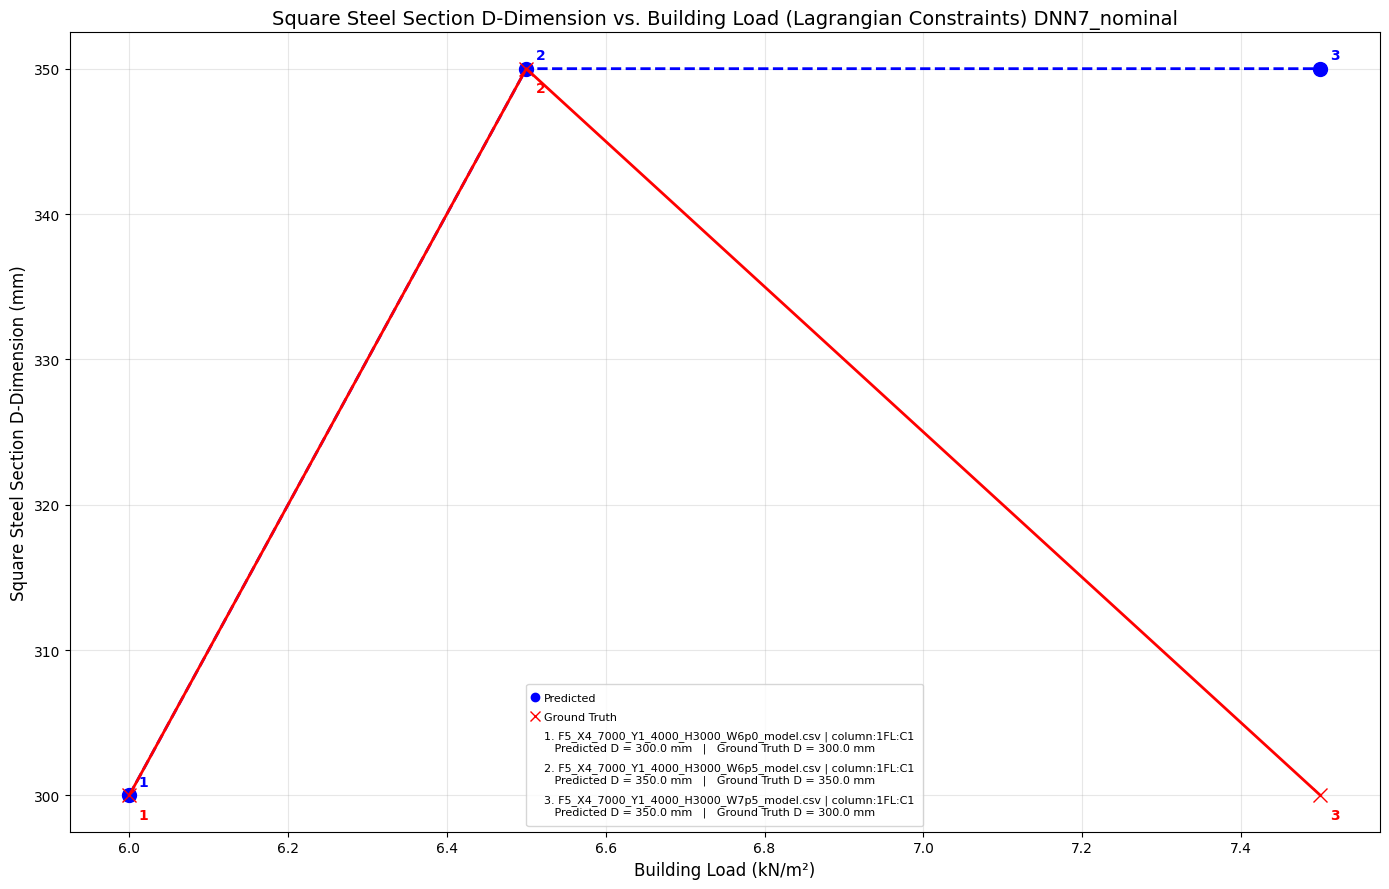

In [24]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


# ============================================================
# 1. Load CSV
# ============================================================

# Adjust the path below to match where your file is located.
# file_path = '/content/drive/My Drive/research/DNN6/dnn_result/test_catalog_predictions_lagrangian.csv'
# df = pd.read_csv(file_path)


# ============================================================
# 2. Extract building load from file_name
# ============================================================

def extract_load(file_name):
    """
    Extract the building load from the file name.

    Example:
        F1_X1_5000_Y1_4000_H3000_W8p0_model.csv

    W8p0 -> load = 8.0 kN/m²
    """

    match = re.search(
        r'_W([\d.]+p?[\d]*)_',
        file_name
    )

    if match is None:
        return pd.NA

    load_str = match.group(1).replace('p', '.')

    return float(load_str)


# Create/update the load column
df['load'] = df['file_name'].apply(
    extract_load
)


# ============================================================
# 3. Create building-condition key
# ============================================================

def create_building_condition_key(file_name, slot):
    """
    Create a building-condition key while excluding
    the building load W.

    Example:

        F1_X1_5000_Y1_4000_H3000_W8p0_model.csv

    becomes:

        F1_X1_5000_Y1_4000_H3000_WLOAD_model.csv

    Therefore, the following conditions are kept constant:

        - Floor
        - X-span count
        - X-span length
        - Y-span count
        - Y-span length
        - Story height
        - Column slot

    while only the building load W is allowed to vary.
    """

    if pd.isna(file_name) or pd.isna(slot):
        return pd.NA

    # Replace ONLY the W/load portion of the filename.
    #
    # W8p0 -> WLOAD
    # W7p0 -> WLOAD
    # W6p5 -> WLOAD
    #
    # Everything else remains unchanged.
    normalized_file_name = re.sub(
        r'_W[\d.]+p?[\d]*_',
        '_WLOAD_',
        file_name
    )

    return f'{normalized_file_name} | {slot}'


df['building_condition_key'] = df.apply(
    lambda row: create_building_condition_key(
        row['file_name'],
        row['slot']
    ),
    axis=1
)


# ============================================================
# 4. Select square steel sections
# ============================================================

# In the provided dataframe:
#
# section_type == 'box'
#
# corresponds to square steel sections.
#
# We also restrict the selection to column members.

df_box = df[
    (df['section_type'] == 'box') &
    (df['slot'].str.startswith('column:', na=False))
].copy()


# ============================================================
# 5. Remove rows with missing required values
# ============================================================

df_box = df_box.dropna(
    subset=[
        'load',
        'pred_D',
        'true_D',
        'file_name',
        'slot',
        'building_condition_key'
    ]
)


# ============================================================
# 6. Find the most consistent building condition
# ============================================================

# Count how many DISTINCT load values are available
# for each building condition.

condition_coverage = (
    df_box
    .groupby('building_condition_key')['load']
    .nunique()
    .reset_index(name='number_of_load_values')
)


# Find the maximum load coverage.

max_coverage = condition_coverage[
    'number_of_load_values'
].max()


# Keep only the building conditions that have
# the maximum number of load values.

best_conditions = condition_coverage[
    condition_coverage['number_of_load_values']
    == max_coverage
].copy()


# ------------------------------------------------------------
# If several building conditions have identical coverage,
# use a deterministic alphabetical tie-breaker.
# ------------------------------------------------------------

best_conditions = best_conditions.sort_values(
    'building_condition_key'
)


selected_condition = best_conditions.iloc[0][
    'building_condition_key'
]


# ============================================================
# 7. Keep ONLY the selected building condition
# ============================================================

df_selected = df_box[
    df_box['building_condition_key']
    == selected_condition
].copy()


# ============================================================
# 8. Select ONE component for each load value
# ============================================================

# Sort first so that the selection is deterministic.

df_selected = df_selected.sort_values(
    [
        'load',
        'file_name',
        'slot'
    ]
)


# Keep exactly one component for each load value.

summary = (
    df_selected
    .drop_duplicates(
        subset='load',
        keep='first'
    )
    .sort_values('load')
    .reset_index(drop=True)
)


# ============================================================
# 9. Check that data exist
# ============================================================

if summary.empty:
    raise ValueError(
        'No valid square steel column data were found in the CSV file.'
    )


# ============================================================
# 10. Generate graph
# ============================================================

fig, ax = plt.subplots(
    figsize=(14, 9)
)


# ============================================================
# 11. Plot predicted D-dimension
# ============================================================

ax.plot(
    summary['load'],
    summary['pred_D'],
    marker='o',
    linestyle='--',
    color='blue',
    linewidth=2,
    markersize=10,
    label='Predicted'
)


# ============================================================
# 12. Plot ground-truth D-dimension
# ============================================================

ax.plot(
    summary['load'],
    summary['true_D'],
    marker='x',
    linestyle='-',
    color='red',
    linewidth=2,
    markersize=10,
    label='Ground Truth'
)


# ============================================================
# 13. Add numbers to the plotted points
# ============================================================

for i, (_, row) in enumerate(
    summary.iterrows(),
    start=1
):

    # --------------------------------------------------------
    # Number next to predicted point
    # --------------------------------------------------------

    ax.annotate(
        str(i),
        xy=(
            row['load'],
            row['pred_D']
        ),
        xytext=(7, 7),
        textcoords='offset points',
        color='blue',
        fontsize=10,
        fontweight='bold'
    )

    # --------------------------------------------------------
    # Number next to ground-truth point
    # --------------------------------------------------------

    ax.annotate(
        str(i),
        xy=(
            row['load'],
            row['true_D']
        ),
        xytext=(7, -17),
        textcoords='offset points',
        color='red',
        fontsize=10,
        fontweight='bold'
    )


# ============================================================
# 14. Create CUSTOM legend
# ============================================================

# ------------------------------------------------------------
# First: explain the two plotted lines
# ------------------------------------------------------------

legend_handles = [
    Line2D(
        [0],
        [0],
        color='blue',
        linestyle='--',
        marker='o',
        linewidth=1.5,
        markersize=6,
        label='Predicted'
    ),

    Line2D(
        [0],
        [0],
        color='red',
        linestyle='-',
        marker='x',
        linewidth=1.5,
        markersize=7,
        label='Ground Truth'
    )
]


# ------------------------------------------------------------
# Second: add one legend entry for each component
# ------------------------------------------------------------

for i, (_, row) in enumerate(
    summary.iterrows(),
    start=1
):

    component_name = (
        f'{row["file_name"]} | {row["slot"]}'
    )

    legend_text = (
        f'{i}. {component_name}\n'
        f'   Predicted D = {row["pred_D"]} mm'
        f'   |   Ground Truth D = {row["true_D"]} mm'
    )

    # Invisible legend handle.
    #
    # The number is contained directly in the legend text.
    legend_handles.append(
        Line2D(
            [0],
            [0],
            color='none',
            linestyle='None',
            marker=None,
            label=legend_text
        )
    )


# ------------------------------------------------------------
# Display the custom legend
# ------------------------------------------------------------

ax.legend(
    handles=legend_handles,
    loc='best',
    fontsize=8,
    frameon=True,
    handlelength=0,
    borderpad=0.8,
    labelspacing=0.8
)


# ============================================================
# 15. Axis labels
# ============================================================

ax.set_xlabel(
    'Building Load (kN/m²)',
    fontsize=12
)

ax.set_ylabel(
    'Square Steel Section D-Dimension (mm)',
    fontsize=12
)


# ============================================================
# 16. Title
# ============================================================

if USE_LAGRANGIAN_CONSTRAINTS:
    ax.set_title(
        f'Square Steel Section D-Dimension vs. Building Load (Lagrangian Constraints) {dnn}',
        fontsize=14
    )
else:
    ax.set_title(
       f'Square Steel Section D-Dimension vs. Building Load (No Constraints) {dnn}',
        fontsize=14
    )


# ============================================================
# 17. Grid
# ============================================================

ax.grid(
    True,
    alpha=0.3
)


# ============================================================
# 18. Adjust layout
# ============================================================

plt.tight_layout()


# ============================================================
# 19. Save graph
# ============================================================

save_dir = OUTPUT_DIR

os.makedirs(
    save_dir,
    exist_ok=True
)
if USE_LAGRANGIAN_CONSTRAINTS:
    output_path = os.path.join(
        save_dir,
        f'{dnn}_Square_Steel_D_Dimension_vs_Building_Load_Lagrangian.png'
    )
else:
    output_path = os.path.join(
        save_dir,
        f'{dnn}_Square_Steel_D_Dimension_vs_Building_Load_No_Lagrangian.png'
    )

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches='tight'
)


# ============================================================
# 20. Download graph
# ============================================================

files.download(
    output_path
)


# ============================================================
# 21. Output selected building condition
# ============================================================

print(
    f'Saved graph to: {output_path}'
)

print('\nSelected building condition:')
print('=' * 120)

print(
    f'Building condition key: {selected_condition}'
)

print(
    f'Number of load values available for this condition: '
    f'{max_coverage}'
)

print(
    f'Load values plotted: '
    f'{summary["load"].tolist()}'
)


# ============================================================
# 22. Output plotted components to terminal
# ============================================================

print('\nSquare steel components plotted:')
print('=' * 120)

for i, (_, row) in enumerate(
    summary.iterrows(),
    start=1
):

    component_name = (
        f'{row["file_name"]} | {row["slot"]}'
    )

    print(
        f'[{i}] Load: {row["load"]:g} kN/m²'
    )

    print(
        f'    Component: {component_name}'
    )

    print(
        f'    Predicted D:    {row["pred_D"]} mm'
    )

    print(
        f'    Ground Truth D: {row["true_D"]} mm'
    )

    print('-' * 120)


print(
    f'Total number of unique load values plotted: '
    f'{summary["load"].nunique()}'
)


# ============================================================
# 23. Display graph
# ============================================================

plt.show()

### Square_Steel_D_Dimension_vs_Floor_C1.png

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved graph to: /content/drive/MyDrive/research/dnn7/dnn-result/DNN7_nominal_Square_Steel_D_Dimension_vs_Floor_C1_with_Constraints.png

Selected building condition:
Building condition key: F5_X1_4000_Y1_4000_H3000_W6p5_model.csv | column:FL:C1
Number of floors available for this condition: 5
Floors plotted: [1, 2, 3, 4, 5]

C1 square steel components plotted:
[1] Floor: 1
    Component: F5_X1_4000_Y1_4000_H3000_W6p5_model.csv | column:1FL:C1
    Predicted D:    150.0 mm
    Ground Truth D: 200.0 mm
------------------------------------------------------------------------------------------------------------------------
[2] Floor: 2
    Component: F5_X1_4000_Y1_4000_H3000_W6p5_model.csv | column:2FL:C1
    Predicted D:    150.0 mm
    Ground Truth D: 200.0 mm
------------------------------------------------------------------------------------------------------------------------
[3] Floor: 3
    Component: F5_X1_4000_Y1_4000_H3000_W6p5_model.csv | column:3FL:C1
    Predicted D:    150.0 mm

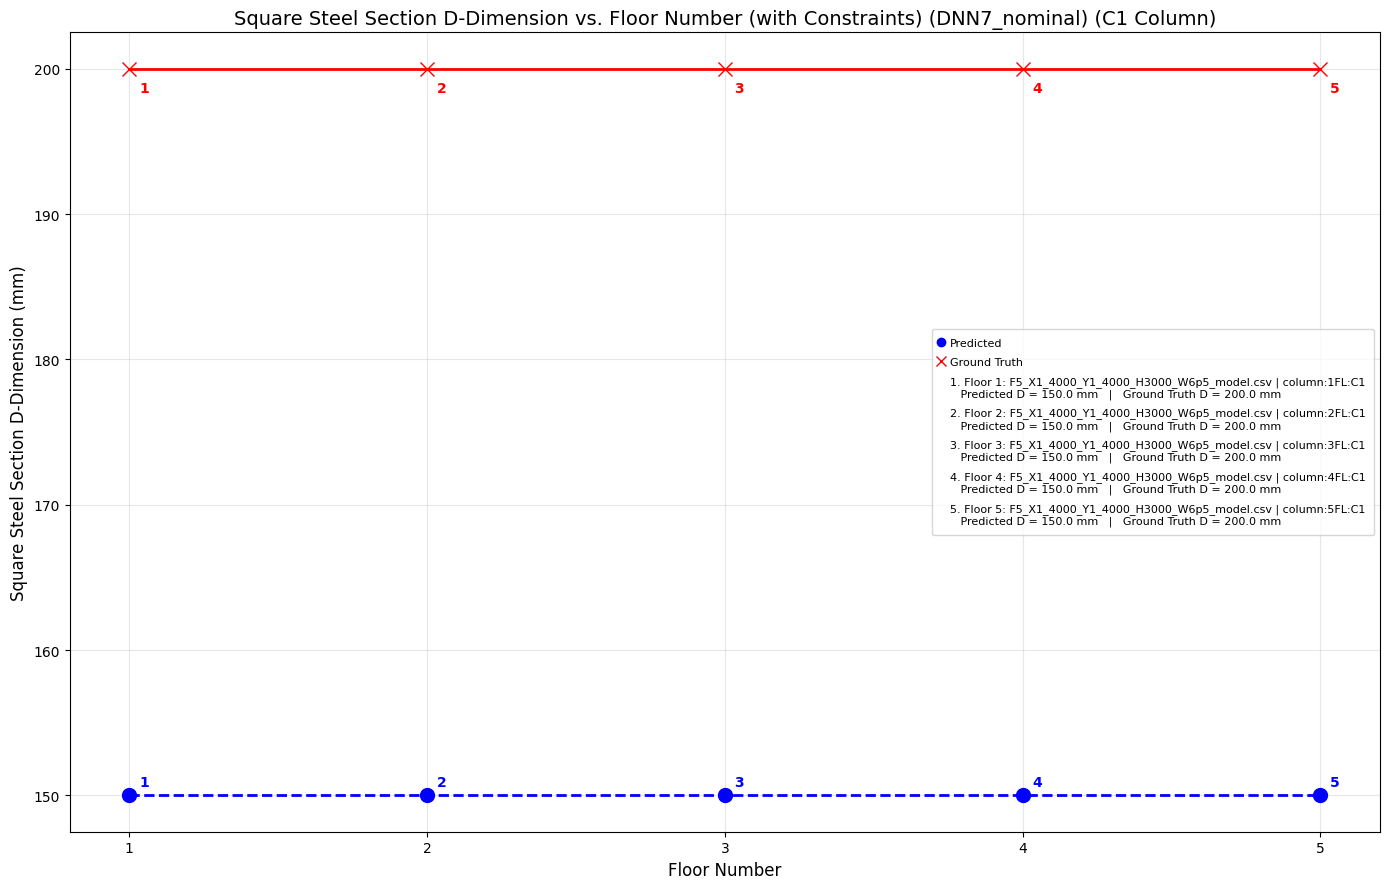

In [25]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


# ============================================================
# 1. Load CSV
# ============================================================

# Adjust the path below to match where your file is located.
# file_path = '/content/drive/My Drive/research/DNN6/dnn_result/test_catalog_predictions_lagrangian.csv'
# df = pd.read_csv(file_path)


# ============================================================
# 2. Extract floor number from slot
# ============================================================

def extract_floor(slot):
    """
    Extract the floor number from a C1 column slot.

    Examples:
        column:1FL:C1 -> 1
        column:2FL:C1 -> 2
        column:3FL:C1 -> 3
        column:5FL:C1 -> 5
    """

    match = re.search(
        r'^column:(\d+)FL:C1$',
        str(slot)
    )

    if match is None:
        return pd.NA

    return int(match.group(1))


df['floor'] = df['slot'].apply(
    extract_floor
)


# ============================================================
# 3. Create building-condition key
# ============================================================

def create_building_condition_key(file_name, slot):
    """
    Create a building-condition key while excluding
    the floor number.

    Example:

        column:1FL:C1
        column:2FL:C1
        column:3FL:C1

    are all converted to:

        column:FL:C1

    The filename is kept unchanged.

    Therefore, the following conditions remain constant:

        - Building configuration represented by file_name
        - X-span count
        - X-span length
        - Y-span count
        - Y-span length
        - Story height
        - Building load
        - C1 column position

    while the FLOOR NUMBER is allowed to vary.
    """

    if pd.isna(file_name) or pd.isna(slot):
        return pd.NA

    # Remove the floor number from the C1 column slot.
    #
    # column:1FL:C1 -> column:FL:C1
    # column:2FL:C1 -> column:FL:C1
    # column:3FL:C1 -> column:FL:C1
    # etc.

    normalized_slot = re.sub(
        r'^column:\d+FL:C1$',
        'column:FL:C1',
        str(slot)
    )

    return f'{file_name} | {normalized_slot}'


df['building_condition_key'] = df.apply(
    lambda row: create_building_condition_key(
        row['file_name'],
        row['slot']
    ),
    axis=1
)


# ============================================================
# 4. Select square steel sections for C1 columns
# ============================================================

# The dataframe uses:
#
#     section_type == 'box'
#
# for square steel sections.
#
# The C1 column slots are:
#
#     column:1FL:C1
#     column:2FL:C1
#     column:3FL:C1
#     ...
#
# Therefore, select only box sections corresponding
# to C1 columns.

df_box_c1 = df[
    (df['section_type'] == 'box') &
    (df['slot'].str.match(
        r'^column:\d+FL:C1$',
        na=False
    ))
].copy()


# ============================================================
# 5. Remove rows with missing required values
# ============================================================

df_box_c1 = df_box_c1.dropna(
    subset=[
        'floor',
        'pred_D',
        'true_D',
        'file_name',
        'slot',
        'building_condition_key'
    ]
)


# ============================================================
# 6. Convert floor number to integer
# ============================================================

df_box_c1['floor'] = (
    df_box_c1['floor']
    .astype(int)
)


# ============================================================
# 7. Find the most consistent building condition
# ============================================================

# Count how many DISTINCT floors are available
# for each building condition.

condition_coverage = (
    df_box_c1
    .groupby('building_condition_key')['floor']
    .nunique()
    .reset_index(name='number_of_floors')
)


# Find the maximum number of floors represented
# by any single building condition.

max_coverage = condition_coverage[
    'number_of_floors'
].max()


# Keep only building conditions having the maximum
# floor coverage.

best_conditions = condition_coverage[
    condition_coverage['number_of_floors']
    == max_coverage
].copy()


# ------------------------------------------------------------
# If multiple conditions have the same coverage,
# use a deterministic alphabetical tie-breaker.
# ------------------------------------------------------------

best_conditions = best_conditions.sort_values(
    'building_condition_key'
)


selected_condition = best_conditions.iloc[0][
    'building_condition_key'
]


# ============================================================
# 8. Keep ONLY the selected building condition
# ============================================================

df_selected = df_box_c1[
    df_box_c1['building_condition_key']
    == selected_condition
].copy()


# ============================================================
# 9. Select ONE component for each floor
# ============================================================

# Sort first to make the selection deterministic.

df_selected = df_selected.sort_values(
    [
        'floor',
        'file_name',
        'slot'
    ]
)


# Keep exactly one C1 component for each floor.

summary = (
    df_selected
    .drop_duplicates(
        subset='floor',
        keep='first'
    )
    .sort_values('floor')
    .reset_index(drop=True)
)


# ============================================================
# 10. Check that data exist
# ============================================================

if summary.empty:
    raise ValueError(
        'No valid C1 square steel column data were found '
        'in the CSV file.'
    )


# ============================================================
# 11. Generate graph
# ============================================================

fig, ax = plt.subplots(
    figsize=(14, 9)
)


# ============================================================
# 12. Plot predicted D-dimension
# ============================================================

ax.plot(
    summary['floor'],
    summary['pred_D'],
    marker='o',
    linestyle='--',
    color='blue',
    linewidth=2,
    markersize=10,
    label='Predicted'
)


# ============================================================
# 13. Plot ground-truth D-dimension
# ============================================================

ax.plot(
    summary['floor'],
    summary['true_D'],
    marker='x',
    linestyle='-',
    color='red',
    linewidth=2,
    markersize=10,
    label='Ground Truth'
)


# ============================================================
# 14. Add numbers to the plotted points
# ============================================================

for i, (_, row) in enumerate(
    summary.iterrows(),
    start=1
):

    # --------------------------------------------------------
    # Number next to predicted point
    # --------------------------------------------------------

    ax.annotate(
        str(i),
        xy=(
            row['floor'],
            row['pred_D']
        ),
        xytext=(7, 7),
        textcoords='offset points',
        color='blue',
        fontsize=10,
        fontweight='bold'
    )

    # --------------------------------------------------------
    # Number next to ground-truth point
    # --------------------------------------------------------

    ax.annotate(
        str(i),
        xy=(
            row['floor'],
            row['true_D']
        ),
        xytext=(7, -17),
        textcoords='offset points',
        color='red',
        fontsize=10,
        fontweight='bold'
    )


# ============================================================
# 15. Create custom legend
# ============================================================

# ------------------------------------------------------------
# First: explain the two plotted line types
# ------------------------------------------------------------

legend_handles = [
    Line2D(
        [0],
        [0],
        color='blue',
        linestyle='--',
        marker='o',
        linewidth=1.5,
        markersize=6,
        label='Predicted'
    ),

    Line2D(
        [0],
        [0],
        color='red',
        linestyle='-',
        marker='x',
        linewidth=1.5,
        markersize=7,
        label='Ground Truth'
    )
]


# ------------------------------------------------------------
# Second: add one legend entry for each numbered floor
# ------------------------------------------------------------

for i, (_, row) in enumerate(
    summary.iterrows(),
    start=1
):

    component_name = (
        f'{row["file_name"]} | {row["slot"]}'
    )

    legend_text = (
        f'{i}. Floor {row["floor"]}: {component_name}\n'
        f'   Predicted D = {row["pred_D"]} mm'
        f'   |   Ground Truth D = {row["true_D"]} mm'
    )

    # Invisible handle.
    #
    # The number is included directly in the legend text.
    legend_handles.append(
        Line2D(
            [0],
            [0],
            color='none',
            linestyle='None',
            marker=None,
            label=legend_text
        )
    )


# ------------------------------------------------------------
# Display custom legend
# ------------------------------------------------------------

ax.legend(
    handles=legend_handles,
    loc='best',
    fontsize=8,
    frameon=True,
    handlelength=0,
    borderpad=0.8,
    labelspacing=0.8
)


# ============================================================
# 16. Axis labels
# ============================================================

ax.set_xlabel(
    'Floor Number',
    fontsize=12
)

ax.set_ylabel(
    'Square Steel Section D-Dimension (mm)',
    fontsize=12
)


# ============================================================
# 17. Title
# ============================================================

if USE_LAGRANGIAN_CONSTRAINTS:
  ax.set_title(
    f'Square Steel Section D-Dimension vs. Floor Number (with Constraints) ({dnn}) '
    '(C1 Column)',
    fontsize=14
)
else:
    ax.set_title(
    f'Square Steel Section D-Dimension vs. Floor Number (without Constraints) ({dnn}) '
    '(C1 Column)',
    fontsize=14
)



# ============================================================
# 18. Set x-axis ticks
# ============================================================

ax.set_xticks(
    summary['floor']
)


# ============================================================
# 19. Grid
# ============================================================

ax.grid(
    True,
    alpha=0.3
)


# ============================================================
# 20. Adjust layout
# ============================================================

plt.tight_layout()


# ============================================================
# 21. Save graph
# ============================================================

save_dir = OUTPUT_DIR

os.makedirs(
    save_dir,
    exist_ok=True
)

if USE_LAGRANGIAN_CONSTRAINTS:
  output_path = os.path.join(
    save_dir,
    f'{dnn}_Square_Steel_D_Dimension_vs_Floor_C1_with_Constraints.png'
  )
else:
  output_path = os.path.join(
    save_dir,
    f'{dnn}_Square_Steel_D_Dimension_vs_Floor_C1_without_Constraints.png'
  )

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches='tight'
)


# ============================================================
# 22. Download graph
# ============================================================

files.download(
    output_path
)


# ============================================================
# 23. Output selected building condition
# ============================================================

print(
    f'Saved graph to: {output_path}'
)

print('\nSelected building condition:')
print('=' * 120)

print(
    f'Building condition key: {selected_condition}'
)

print(
    f'Number of floors available for this condition: '
    f'{max_coverage}'
)

print(
    f'Floors plotted: '
    f'{summary["floor"].tolist()}'
)


# ============================================================
# 24. Output plotted components to terminal
# ============================================================

print('\nC1 square steel components plotted:')
print('=' * 120)

for i, (_, row) in enumerate(
    summary.iterrows(),
    start=1
):

    component_name = (
        f'{row["file_name"]} | {row["slot"]}'
    )

    print(
        f'[{i}] Floor: {row["floor"]}'
    )

    print(
        f'    Component: {component_name}'
    )

    print(
        f'    Predicted D:    {row["pred_D"]} mm'
    )

    print(
        f'    Ground Truth D: {row["true_D"]} mm'
    )

    print('-' * 120)


print(
    f'Total number of floors plotted: '
    f'{summary["floor"].nunique()}'
)


# ============================================================
# 25. Display graph
# ============================================================

plt.show()

## Model visualization

In [26]:
!pip install torchinfo

In [32]:
from torchinfo import summary

# summary(model, input_size=(1, N_FEATURES))
summary(model, input_size=(1, len(FEATURE_NAMES)))

Layer (type:depth-idx)                   Output Shape              Param #
FloorAwareDNN                            [1, 20, 22]               --
├─Sequential: 1-1                        [1, 128]                  --
│    └─Linear: 2-1                       [1, 128]                  4,096
│    └─ReLU: 2-2                         [1, 128]                  --
│    └─Linear: 2-3                       [1, 128]                  16,512
│    └─ReLU: 2-4                         [1, 128]                  --
├─Embedding: 1-2                         [20, 32]                  640
├─Embedding: 1-3                         [20, 16]                  96
├─Embedding: 1-4                         [20, 16]                  32
├─Linear: 1-5                            [1, 20, 22]               4,246
├─Linear: 1-6                            [1, 20, 58]               11,194
Total params: 36,816
Trainable params: 36,816
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.05
Input size (MB): 0.00
Forward/

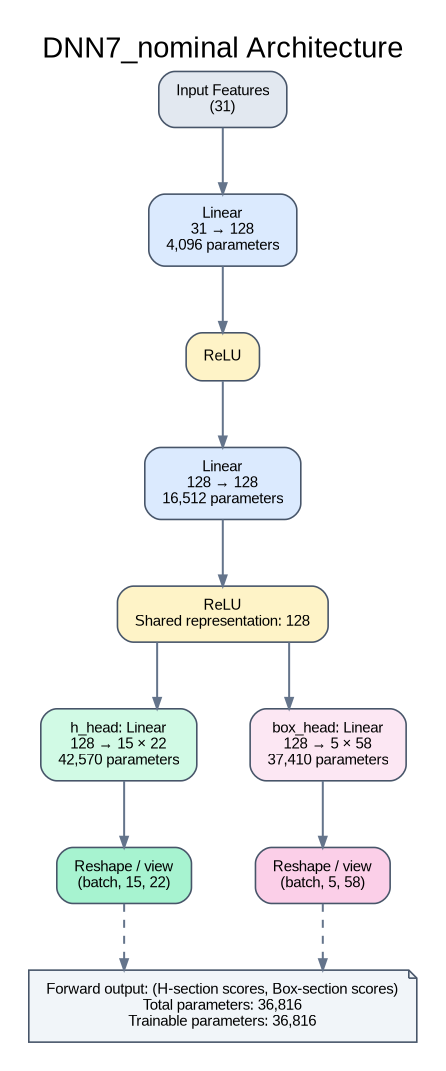

Saved diagram: /content/drive/MyDrive/research/dnn7/dnn-result/DNN7_nominal_architecture.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:

!apt-get -qq install -y graphviz
!pip -q install graphviz

from graphviz import Digraph
from IPython.display import display, Image
from google.colab import files





_nf = len(FEATURE_NAMES)
_h_out = N_H_SLOTS * len(H_CATALOG); _box_out = N_BOX_SLOTS * len(BOX_CATALOG)
_total_params = sum(p.numel() for p in model.parameters())
_trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

dot = Digraph(f"{dnn}", format="png", engine="dot")

dot.attr(
    rankdir="TB",
    bgcolor="white",
    pad="0.3",
    nodesep="0.55",
    ranksep="0.7",
    splines="ortho",
    label=f"{dnn} Architecture",
    labelloc="t",
    fontsize="22",
    fontname="Arial"
)

dot.attr(
    "node",
    shape="box",
    style="rounded,filled",
    fontname="Arial",
    fontsize="11",
    margin="0.18,0.12",
    color="#475569",
    penwidth="1.2"
)

dot.attr(
    "edge",
    color="#64748b",
    penwidth="1.5",
    arrowsize="0.8"
)

# ------------------------------------------------------------

# ------------------------------------------------------------
dot.node(
    "input",
    f"Input Features\n({_nf})",
    fillcolor="#E2E8F0"
)

# ------------------------------------------------------------

# ------------------------------------------------------------
dot.node(
    "fc1",
    f"Linear\n{_nf} → 128\n{_nf*128+128:,} parameters",
    fillcolor="#DBEAFE"
)

dot.node(
    "relu1",
    "ReLU",
    fillcolor="#FEF3C7"
)

dot.node(
    "fc2",
    "Linear\n128 → 128\n16,512 parameters",
    fillcolor="#DBEAFE"
)

dot.node(
    "relu2",
    "ReLU\nShared representation: 128",
    fillcolor="#FEF3C7"
)

dot.edge("input", "fc1")
dot.edge("fc1", "relu1")
dot.edge("relu1", "fc2")
dot.edge("fc2", "relu2")

# ------------------------------------------------------------

# ------------------------------------------------------------
dot.node(
    "h_head",
    f"h_head: Linear\n128 → {N_H_SLOTS} × {len(H_CATALOG)}\n{128*_h_out+_h_out:,} parameters",
    fillcolor="#D1FAE5"
)

dot.node(
    "h_view",
    f"Reshape / view\n(batch, {N_H_SLOTS}, {len(H_CATALOG)})",
    fillcolor="#A7F3D0"
)

# ------------------------------------------------------------

# ------------------------------------------------------------
dot.node(
    "box_head",
    f"box_head: Linear\n128 → {N_BOX_SLOTS} × {len(BOX_CATALOG)}\n{128*_box_out+_box_out:,} parameters",
    fillcolor="#FCE7F3"
)

dot.node(
    "box_view",
    f"Reshape / view\n(batch, {N_BOX_SLOTS}, {len(BOX_CATALOG)})",
    fillcolor="#FBCFE8"
)


dot.edge("relu2", "h_head")
dot.edge("h_head", "h_view")

dot.edge("relu2", "box_head")
dot.edge("box_head", "box_view")


with dot.subgraph() as s:
    s.attr(rank="same")
    s.node("h_head")
    s.node("box_head")

with dot.subgraph() as s:
    s.attr(rank="same")
    s.node("h_view")
    s.node("box_view")

# ------------------------------------------------------------

# ------------------------------------------------------------
dot.node(
    "output",
    "Forward output: (H-section scores, Box-section scores)\n"
    f"Total parameters: {_total_params:,}\n"
    f"Trainable parameters: {_trainable_params:,}",
    shape="note",
    fillcolor="#F1F5F9"
)

dot.edge("h_view", "output", style="dashed")
dot.edge("box_view", "output", style="dashed")

# ------------------------------------------------------------

# ------------------------------------------------------------
# Define output path base (without extension) so Graphviz appends '.png' correctly
output_path_base = OUTPUT_DIR / f"{dnn}_architecture"
dot.render(output_path_base, cleanup=True)

# The final generated image file path
image_file_path = f"{output_path_base}.png"

display(Image(filename=image_file_path))
print(f"Saved diagram: {image_file_path}")

files.download(image_file_path)
